# Running on qBraid

This notebook is ready to run on **qBraid** with the **QGSS 2026** environment — no `pip install` needed.

1. Make sure the **QGSS 2026** environment is installed.
2. Select the **Python 3 [QGSS 2026]** kernel (kernel picker, top-right), then run the cells.

# Lab 4: Towards quantum advantage

# Chapter 4: Sample-based Quantum Diagonalization

### Table of Contents

- Exercise 1: Map LUCJ circuit to the Nighthawk device
- Exercise 2: Examine the resulting bitstring
- Exercise 3: Recover the bitstring
- Exercise 4: Freeze subspace configurations
- Scored Exercise: Find your best subspace!


In this chapter you will estimate the **ground-state energy** of the nitrogen molecule (N₂) on a real quantum computer using **Sample-based Quantum Diagonalization (SQD)**.

SQD is a hybrid quantum–classical method: the quantum computer runs a parameterized circuit and *proposes* which electron arrangements are most important, while the classical computer does the linear algebra — diagonalizing the molecular Hamiltonian in that small, smartly chosen set of configurations.

By the end of this chapter you will have mapped a chemistry circuit to two different IBM device topologies, cleaned up noisy hardware bitstrings, and beaten the Hartree–Fock energy on real quantum hardware.

## Background: Molecular quantum chemistry in 5 minutes

You do **not** need a chemistry background to complete this lab. This section gives you just enough vocabulary.

### Molecules, orbitals, and electrons

Think of a molecule as a small concert hall.
The **molecular orbitals** are the seats in that hall.
The **electrons** are the guests who must be seated according to one strict rule: each seat (orbital) can hold *at most one guest of a given spin* — this is the Pauli exclusion principle.

Each spatial orbital can host two electrons, one with **spin-α (↑)** and one with **spin-β (↓)**.
We always track the two spin flavors separately, which is exactly why the bitstrings you will measure later are split into an α half and a β half.

### The ground state and why it matters

The **ground state** is the lowest-total-energy seating arrangement.
It tells chemists whether a molecule is stable, how strong its bonds are, and whether it will react.
Computing the ground-state energy accurately is one of the most compelling near-term applications of quantum computers because the number of possible seatings grows *exponentially* — for $n$ orbitals and $N_e$ electrons there are $\binom{n}{N_e}$ arrangements per spin species, which quickly exceeds any classical computer's reach.

Mathematically, the problem is:

$$E_0 = \min_{\psi} \frac{\langle \psi | \hat{H} | \psi \rangle}{\langle \psi | \psi \rangle}$$

We want the lowest eigenvalue of the molecular Hamiltonian $\hat{H}$.

### Classical reference methods

Two classical methods provide the benchmark lines in our plots:

| Method | What it does | Accuracy |
|---|---|---|
| **Hartree–Fock (HF)** | Each electron ignores every other and picks the cheapest seat independently. Fast, but ignores electron *correlation* — the tendency of electrons to dodge each other. | Upper bound on $E_0$; rough estimation. |
| **CCSD** (Coupled Cluster Singles & Doubles) | Starts from HF, then adds 1- and 2-electron "jumps" out of the HF arrangement using algebraic amplitudes $t_1$ (singles) and $t_2$ (doubles). Captures most correlation. | Near-exact for many molecules; our gold-standard comparison. |

> **Key point:** We will also *use* CCSD to seed our quantum circuit — its amplitudes describe how electrons want to jump between orbitals, and we transplant that chemical intuition directly into the parameters of the quantum ansatz.

In [ ]:
# ✅ QGSS 2026 kernel check — run this first.
# Verifies this notebook is running on the 'Python 3 [QGSS 2026]' kernel.
# If it isn't, the output explains exactly how to install/add/select it.
from qbraid_kernel_check import check_qgss_kernel

check_qgss_kernel()

✅ QGSS 2026 kernel is active.
   sys.executable = <LOCAL_ENVIRONMENT_PATH>


True

In [ ]:
# Version display
!uv pip show qiskit qiskit-ibm-runtime qiskit-addon-sqd ffsim

Using Python 3.12.3 environment at: <LOCAL_ENVIRONMENT_PATH>
Name: ffsim
Version: 0.0.80
Location: <LOCAL_ENVIRONMENT_PATH>
Requires: jax, numpy, opt-einsum, orjson, pyscf, qiskit, scipy, typing-extensions
Required-by:
---
Name: qiskit
Version: 2.5.1
Location: <LOCAL_ENVIRONMENT_PATH>
Requires: dill, numpy, rustworkx, scipy, stevedore, typing-extensions
Required-by: ffsim, ibm-quantum-schemas, mthree, pauli-prop, qc-grader, qiskit-addon-opt-mapper, qiskit-addon-pna, qiskit-addon-slc, qiskit-addon-sqd, qiskit-addon-utils, qiskit-aer, qiskit-ibm-runtime, qiskit-qasm3-import, qopt-best-practices, samplomatic
---
Name: qiskit-addon-sqd
Version: 0.12.1
Location: <LOCAL_ENVIRONMENT_PATH>
Requires: jax, jaxlib, numpy, pyscf, qiskit, scipy
Required-by:
---
Name: qiskit-ibm-runtime
Version: 0.48.0
Location: <LOCAL_ENVIRONMENT_PATH>
Requires: ibm-platform-services, ibm-quantum-schemas, numpy, pybase64, pydantic, python-dateutil, qiskit, requests, requests-ntlm, samplomatic, scipy, urllib3
Requir

In [ ]:
# Import necessary packages
import warnings
warnings.filterwarnings("ignore")

import copy
import numpy as np
import matplotlib.pyplot as plt
from collections import defaultdict
from typing import cast
from itertools import combinations
from functools import partial

import pyscf
import pyscf.cc
import pyscf.mcscf
import ffsim

from qiskit.circuit import QuantumCircuit, QuantumRegister, CircuitInstruction, Barrier
from qiskit.transpiler import generate_preset_pass_manager
from qiskit.visualization import plot_error_map
from qiskit_ibm_runtime import QiskitRuntimeService, Sampler
from qiskit_ibm_runtime.fake_provider import FakeMiami

from qiskit_addon_sqd.fermion import SCIResult, solve_sci_batch
from qiskit_addon_sqd.subsampling import subsample
from qiskit_addon_sqd.counts import bit_array_to_arrays, bitstring_matrix_to_integers

In [ ]:
from qc_grader.challenges.qgss_2026 import (
    grade_lab4c_ex1a,
    grade_lab4c_ex1b,
    grade_lab4c_ex2a,
    grade_lab4c_ex2b,
    grade_lab4c_ex3a,
    grade_lab4c_ex3b,
    grade_lab4c_ex4,
    grade_lab4c_exbonus,
)

## 1. Building the N₂ molecule and its Hamiltonian

### The nitrogen molecule

We study **molecular nitrogen (N₂)**: two nitrogen atoms separated by 2.0 Å.
We describe the molecule using the **`cc-pvdz` basis set** — a standard vocabulary of orbital shapes that balances accuracy with computational cost.
Running Hartree–Fock in this basis gives us 28 spatial orbitals in total.

### Active space and frozen orbitals

Not all orbitals matter equally.
The innermost **core** orbitals (the 1s electrons of each nitrogen atom) sit deep in energy and essentially never change — they are perfectly happy where they are no matter what the molecule does.
Computing those orbitals quantum-mechanically would waste precious qubits.

We therefore **freeze** them:
- `n_frozen = 2` removes the 2 lowest-energy core orbitals from the quantum treatment.
- `active_space = range(n_frozen, mol.nao_nr())` is the set of orbitals where the chemically interesting action — bond formation, electron correlation — actually happens.

This is the **active-space approximation**: solve the full HF over everything, then only treat the active-space electrons on the quantum computer.
After freezing, we are left with:
- `num_orbitals` active spatial orbitals → this will equal the number of qubits per spin sector.
- `(num_elec_a, num_elec_b)` active electrons of spin-α and spin-β.  N₂ is a closed-shell singlet, so `num_elec_a == num_elec_b`.

The code cell below also extracts the **one-electron integrals** (`hcore`), **two-electron repulsion integrals** (`eri`), and the constant **nuclear repulsion energy** — together these are the numerical representation of $\hat{H}$ restricted to the active space, which the classical eigensolver will diagonalize later.

In [ ]:
# Build N2 molecule
mol = pyscf.gto.Mole()
mol.build(
    atom=[["N", (0, 0, 0)], ["N", (2.0, 0, 0)]],
    basis="cc-pvdz",
)

# Define active space
n_frozen = 2
active_space = range(n_frozen, mol.nao_nr())

# Get molecular integrals
scf = pyscf.scf.RHF(mol).run()
num_orbitals = len(active_space)
n_electrons = int(sum(scf.mo_occ[active_space]))
num_elec_a = (n_electrons + mol.spin) // 2
num_elec_b = (n_electrons - mol.spin) // 2
cas = pyscf.mcscf.CASCI(scf, num_orbitals, (num_elec_a, num_elec_b))
mo = cas.sort_mo(active_space, base=0)
hcore, nuclear_repulsion_energy = cas.get_h1cas(mo)
eri = pyscf.ao2mo.restore(1, cas.get_h2cas(mo), num_orbitals)

# Print molecular information
print(f"Number of molecular orbitals: {num_orbitals}")
print(f"Number of electrons (a, b): {(num_elec_a, num_elec_b)}")

converged SCF energy = -108.33058275366
Number of molecular orbitals: 26
Number of electrons (a, b): (5, 5)


### Running CCSD to seed the quantum ansatz

Before we build the quantum circuit, we run **CCSD** classically.
We are *not* using CCSD as the final answer — that would defeat the purpose.
We are **mining it for its amplitudes**:

- `t1[i, a]` — the amplitude for a single electron to "jump" from occupied orbital $i$ to virtual orbital $a$.
- `t2[i, j, a, b]` — the amplitude for an electron *pair* to scatter from $(i, j)$ to $(a, b)$.

These amplitudes encode CCSD's chemical intuition about how electrons correlate.
In the next section, the `ffsim` library will read them and compile them into the rotation angles of the quantum circuit, effectively transplanting classical chemistry knowledge into the quantum device as a high-quality starting guess.

In [ ]:
# Get CCSD t2 amplitudes for initializing the ansatz
ccsd = pyscf.cc.CCSD(scf, frozen=[i for i in range(mol.nao_nr()) if i not in active_space]).run(max_cycle=1000)
t1 = ccsd.t1
t2 = ccsd.t2

E(CCSD) = -108.909520691429  E_corr = -0.5789379377692805


## 2. Quantum state preparation: the LUCJ ansatz

### What is the LUCJ ansatz?

The goal of state preparation is to build a quantum circuit that approximates the N₂ ground state well enough that sampling it yields electron configurations close to the true ground state.
We use the **(L)UCJ ansatz** — **(Local) Unitary Cluster Jastrow** — a hardware-efficient parameterized circuit that captures electron correlation through two ingredients:

1. **Orbital rotations** $e^{i\hat{K}}$: one-body unitaries that mix the molecular orbitals (think of them as rearranging the seats).
2. **Jastrow factor** $e^{i\sum_{pq} J_{pq}\,\hat{n}_p \hat{n}_q}$: a diagonal interaction that penalizes or rewards pairs of electrons simultaneously occupying orbitals $p$ and $q$ (electrons react to each other's presence).

One UCJ layer has the form:

$$U_\mu = e^{i\hat{K}_\mu}\; e^{i\sum_{p<q} J^{(\mu)}_{pq}\,\hat{n}_p \hat{n}_q}\; e^{-i\hat{K}_\mu}$$

where $\hat{n}_p = a^\dagger_p a_p$ is the occupation-number operator for orbital $p$.
The full ansatz stacks `n_reps` such layers: $U = U_{n_\text{reps}} \cdots U_1$.
Here we use `n_reps = 1`.

### From CCSD amplitudes to circuit parameters

`ffsim.UCJOpSpinBalanced.from_t_amplitudes(t1, t2, n_reps, interaction_pairs)` reads the CCSD single- and double-excitation amplitudes and compiles them into the rotation angles $K_\mu$ and Jastrow couplings $J_{pq}^{(\mu)}$.
Intuitively: if CCSD says "orbitals $i$ and $a$ swap strongly", the corresponding orbital rotation in $e^{i\hat{K}}$ gets a large angle.

**Spin-balanced** means the α (spin-up) and β (spin-down) sectors share the same orbital-rotation parameters — appropriate for a closed-shell singlet like N₂ (same α and β occupations), and it halves the number of free parameters.

### Interaction pairs — the hardware constraint

The Jastrow factor requires two qubits to interact directly.
The `interaction_pairs` argument tells `ffsim` which pairs of orbitals can interact:

- `alpha_alpha_indices = [(p, p+1) ...]` — same-spin *nearest-neighbor* interactions along the qubit chain (one line per spin sector on the chip).
- `alpha_beta_indices` — **cross-spin** interactions: an α qubit at position $p$ couples to a β qubit at position $q$.
  These are **constrained by the device wiring**: the coupling is only hardware-native if the two physical qubits are neighbors on the chip.

This is the key point of Exercise 1: different IBM devices have different topologies, so the allowed `alpha_beta_indices` differ between a Heron chip and a Nighthawk chip.

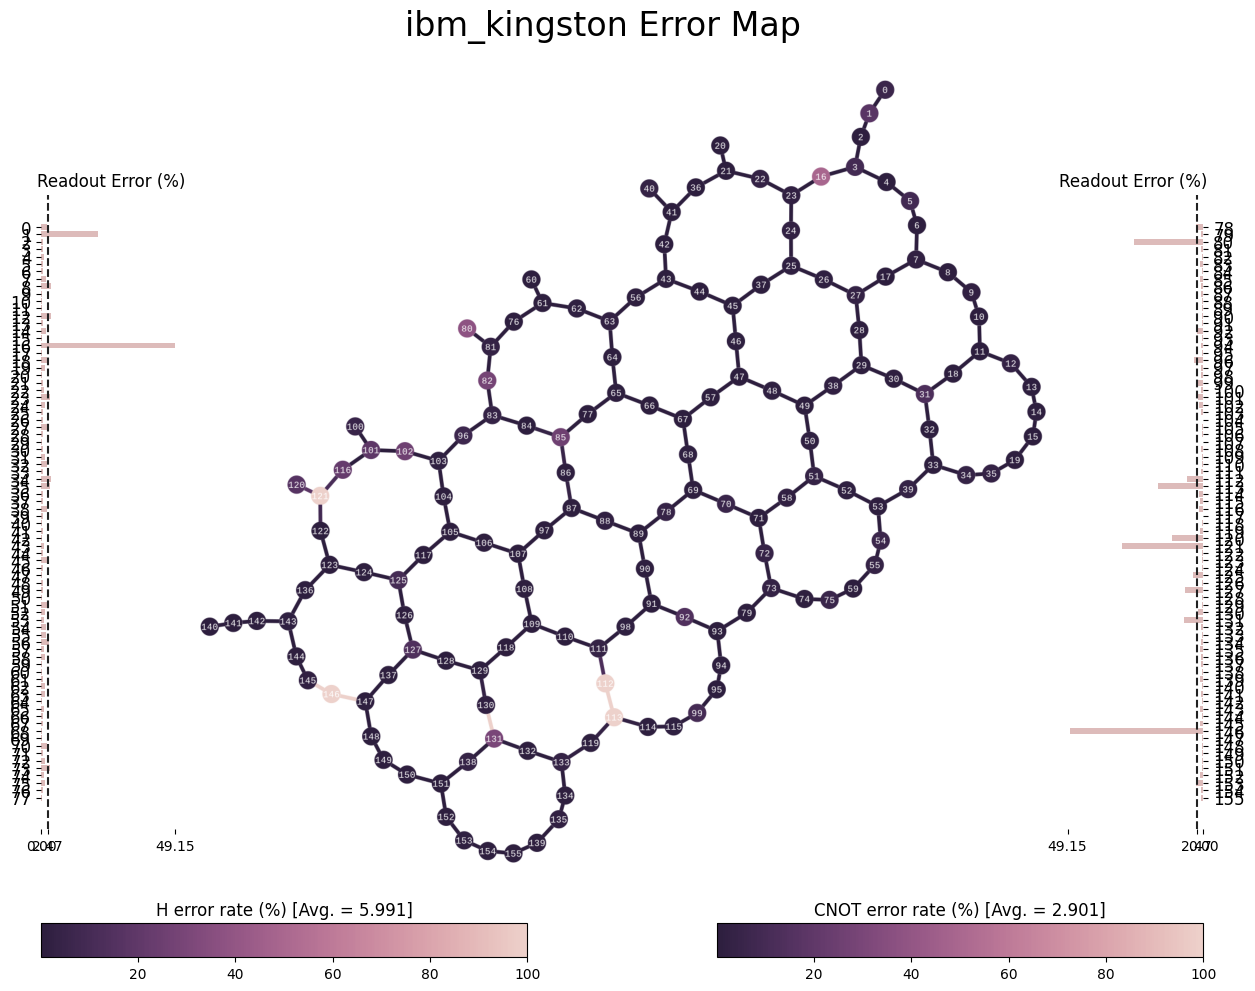

In [ ]:
service = QiskitRuntimeService()
backend_hr = service.backend("ibm_kingston")
plot_error_map(backend_hr)

### Jordan–Wigner encoding: from orbitals to qubits

The **Jordan–Wigner (JW) transformation** is the dictionary that maps fermionic orbital states onto qubit states:

$$\text{orbital } p \text{ occupied} \;\Longleftrightarrow\; \text{qubit } p = |1\rangle, \qquad
  \text{orbital } p \text{ empty} \;\Longleftrightarrow\; \text{qubit } p = |0\rangle$$

We use $2 \times \texttt{num\_orbitals}$ qubits in total:
- Qubits $0, \ldots, \texttt{num\_orbitals}-1$ → spin-α occupations
- Qubits $\texttt{num\_orbitals}, \ldots, 2\cdot\texttt{num\_orbitals}-1$ → spin-β occupations

This is exactly why, much later in Exercise 2a, a measured bitstring of length `2*num_orbitals` splits cleanly into an α half and a β half.

Two `ffsim` circuit instructions handle the encoding:
- `PrepareHartreeFockJW` — sets the initial qubit state to the Hartree–Fock occupation pattern (the first `num_elec_a` α-qubits and `num_elec_b` β-qubits are $|1\rangle$, the rest $|0\rangle$).
- `UCJOpSpinBalancedJW` — applies the UCJ correlator in the JW qubit basis.

### PRE_INIT passes and gate counts

The `ffsim.qiskit.PRE_INIT` transpiler pass decomposes the high-level `ffsim` gate objects into native hardware gates *before* the main transpilation pass runs.
Running `count_ops()` with and without `PRE_INIT` shows how many native 2-qubit gates the circuit requires — fewer gates means less accumulated noise.

The code below shows the complete setup for the **Heron (`ibm_kingston`)** device as a worked example.
Exercise 1 asks you to redo this mapping for the **Nighthawk (`ibm_miami`)** device.

### The SQD workflow: a brief map

Once the circuit is ready, the rest of this chapter follows a four-step loop:

1. **Sample** — run the LUCJ circuit on hardware and collect bitstrings.
2. **Recover configurations** — fix bitstrings that noise has pushed to the wrong electron count.
3. **Build a subspace** — collect the most frequent (most probable) electron configurations as a basis.
4. **Diagonalize** $\hat{H}$ in that subspace — get an energy estimate; feed the resulting orbital occupancies back to step 2.

Each iteration the subspace gets a little smarter.

In [ ]:
# For the Heron device, the alpha-beta interaction happens per every four indicies
alpha_alpha_indices = [(p, p + 1) for p in range(num_orbitals - 1)]
alpha_beta_indices_hr = [(p, p) for p in range(0, num_orbitals, 4)]
alpha_beta_indices_hr = alpha_beta_indices_hr[:5]  # truncate at fifth pair

print(alpha_beta_indices_hr)

[(0, 0), (4, 4), (8, 8), (12, 12), (16, 16)]


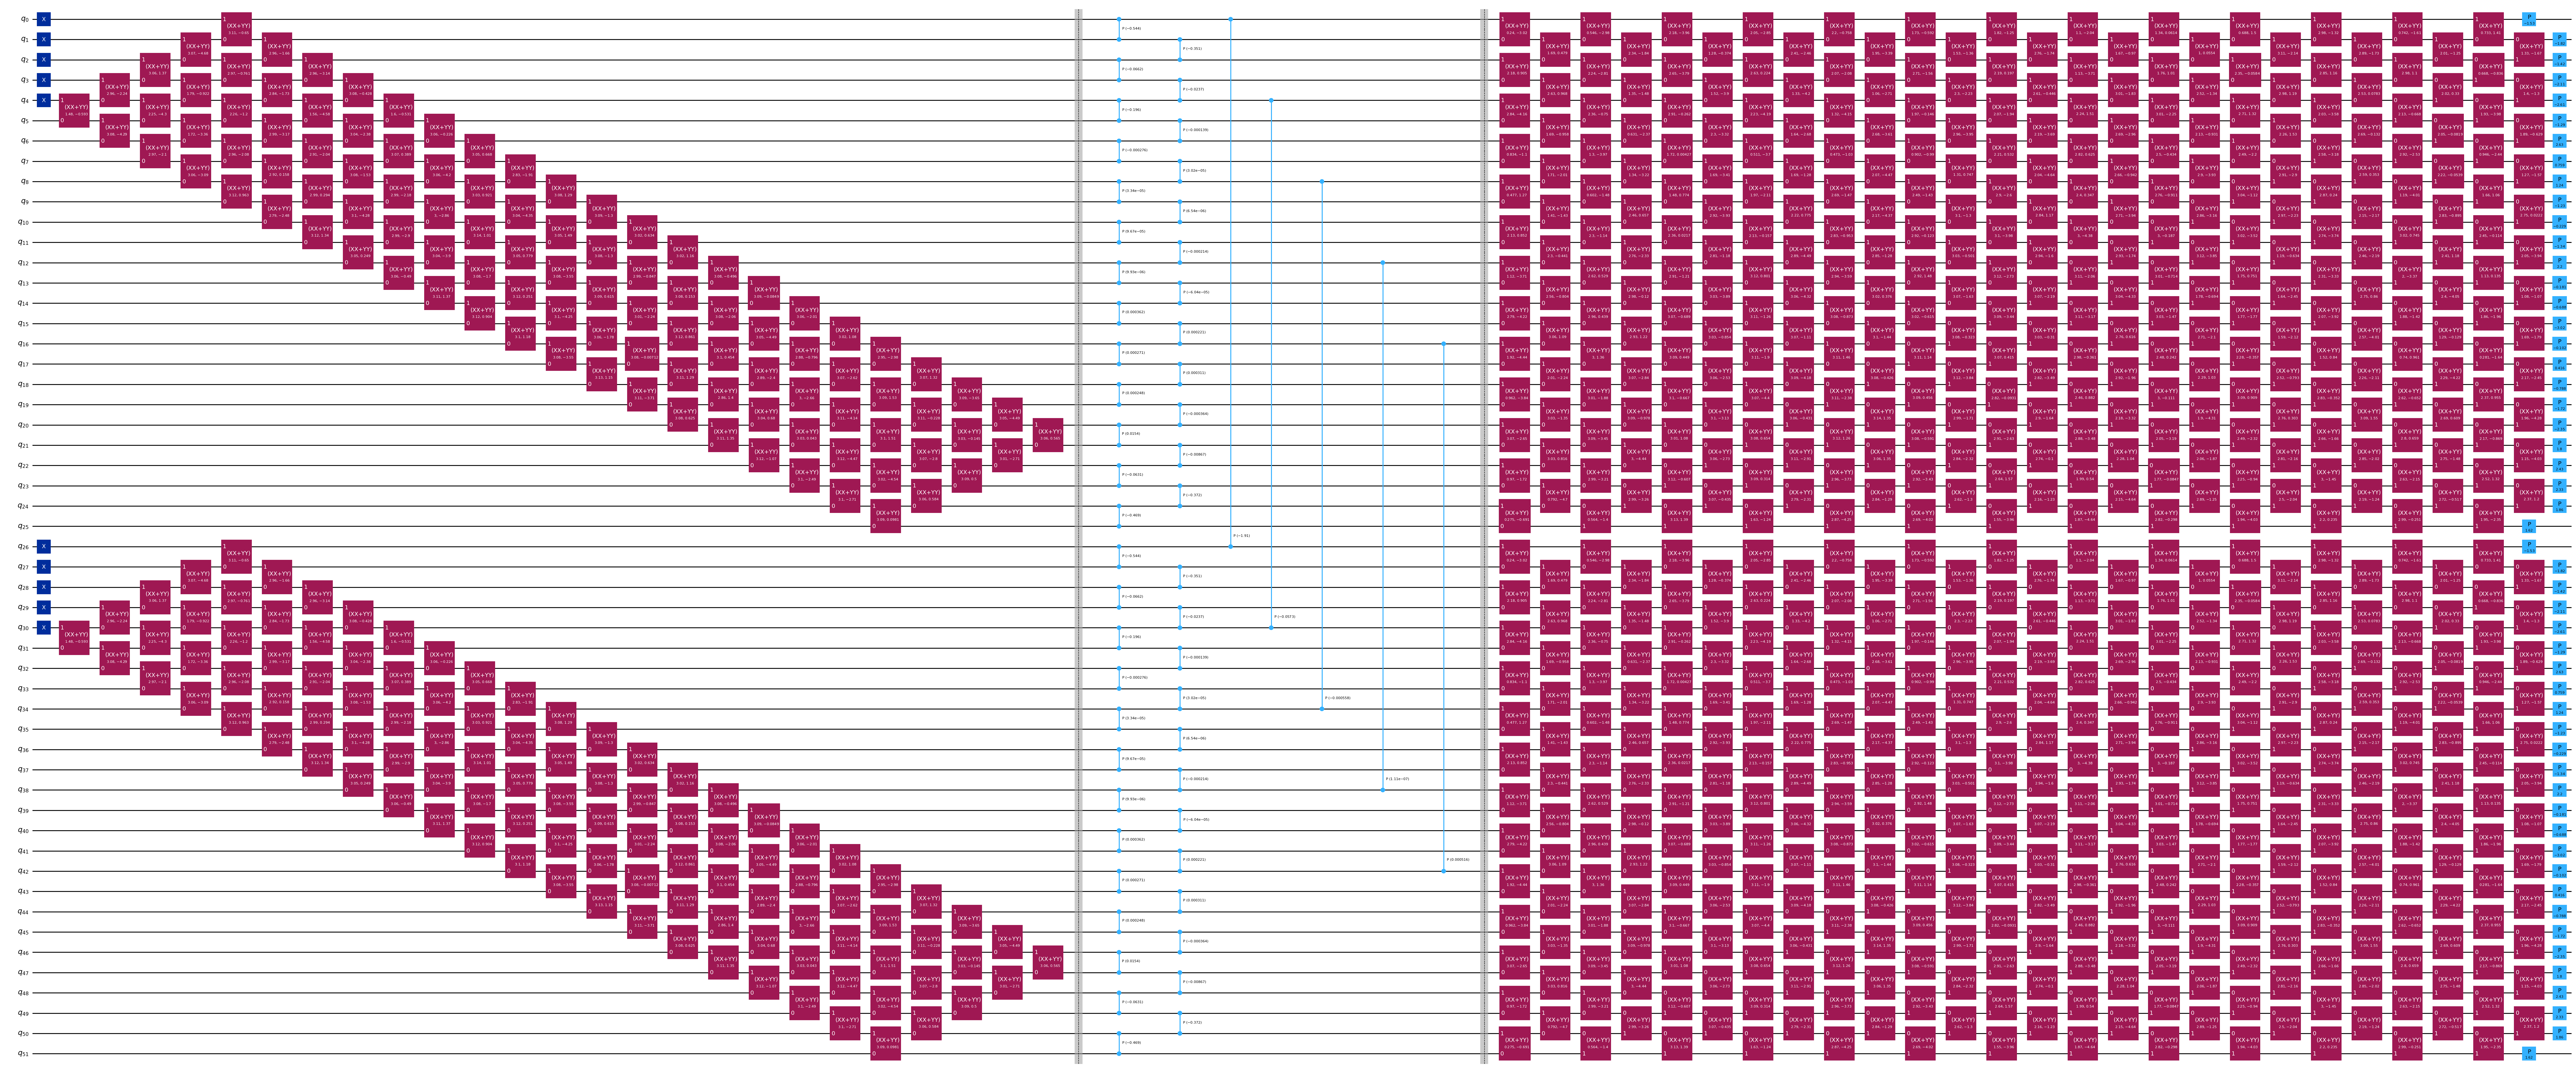

In [ ]:
n_reps = 1
ucj_op_hr = ffsim.UCJOpSpinBalanced.from_t_amplitudes(
    t1=t1,
    t2=t2,
    n_reps=n_reps,
    interaction_pairs=(alpha_alpha_indices, alpha_beta_indices_hr),
    optimize=True,
    options=dict(maxiter=20),
)
nelec = (num_elec_a, num_elec_b)

# create an empty quantum circuit
qubits = QuantumRegister(2 * num_orbitals, name="q")
circuit_hr = QuantumCircuit(qubits)

# prepare Hartree-Fock state as the reference state and append it to the quantum circuit
circuit_hr.append(ffsim.qiskit.PrepareHartreeFockJW(num_orbitals, nelec), qubits)

# apply the UCJ operator to the reference state
circuit_hr.append(ffsim.qiskit.UCJOpSpinBalancedJW(ucj_op_hr), qubits)

# investigate into the circuit for execution
inner_circuit_hr = ffsim.qiskit.PRE_INIT.run(circuit_hr)
for i in range(2, 0, -1):
    inner_circuit_hr.data.insert(i, CircuitInstruction(Barrier(num_qubits=2*num_orbitals), qubits))
display(inner_circuit_hr.decompose().draw("mpl", fold=-1))

# insert final measurement
circuit_hr.measure_all()

In [ ]:
# select spin a and b layout according to the device topology
spin_a_layout = [
     21,  36,  41,  42,  43,     56,  63,  64,  65,  77,
     85,  86,  87,  97, 107,    108, 109, 118, 129, 128,
    127, 126, 125, 117, 105,    104
]
spin_b_layout = [
     23,  24,  25,  37,  45,     46,  47,  57,  67,  68,
     69,  78,  89,  90,  91,     98, 111, 112, 113, 114,
    115,  99,  95,  94,  93,     79
]

initial_layout = spin_a_layout + spin_b_layout

pass_manager = generate_preset_pass_manager(
    optimization_level=3, backend=backend_hr, initial_layout=initial_layout
)

# without PRE_INIT passes
isa_circuit_hr = pass_manager.run(circuit_hr)
print(f"Gate counts (w/o pre-init passes): {isa_circuit_hr.count_ops()}")

# with PRE_INIT passes
# We will use the circuit generated by this pass manager for hardware execution
pass_manager.pre_init = ffsim.qiskit.PRE_INIT
isa_circuit_hr = pass_manager.run(circuit_hr)
print(f"Gate counts (w/ pre-init passes): {isa_circuit_hr.count_ops()}")

Gate counts (w/o pre-init passes): OrderedDict({'sx': 11651, 'rz': 11616, 'cz': 3480, 'x': 394, 'measure': 52, 'barrier': 1})
Gate counts (w/ pre-init passes): OrderedDict({'sx': 6969, 'rz': 6923, 'cz': 1820, 'measure': 52, 'x': 44, 'barrier': 1})


## Exercise 1: Map LUCJ circuit for the Nighthawk device

Now let's port the same circuit to the **Nighthawk (`ibm_miami`)** device.
Run the error-map cell below and compare the connectivity diagram to Heron's.
Notice how the α and β qubit rails are wired differently — that changes which cross-spin interaction pairs are hardware-native.

> **No access to `ibm_miami`?** Use `FakeMiami` instead — uncomment the second line in the cell below. `FakeMiami` reproduces the Nighthawk device topology (same qubit graph and basis gates) so the circuit mapping and layout exercises work identically; the only difference is that it simulates noise rather than running on real hardware.

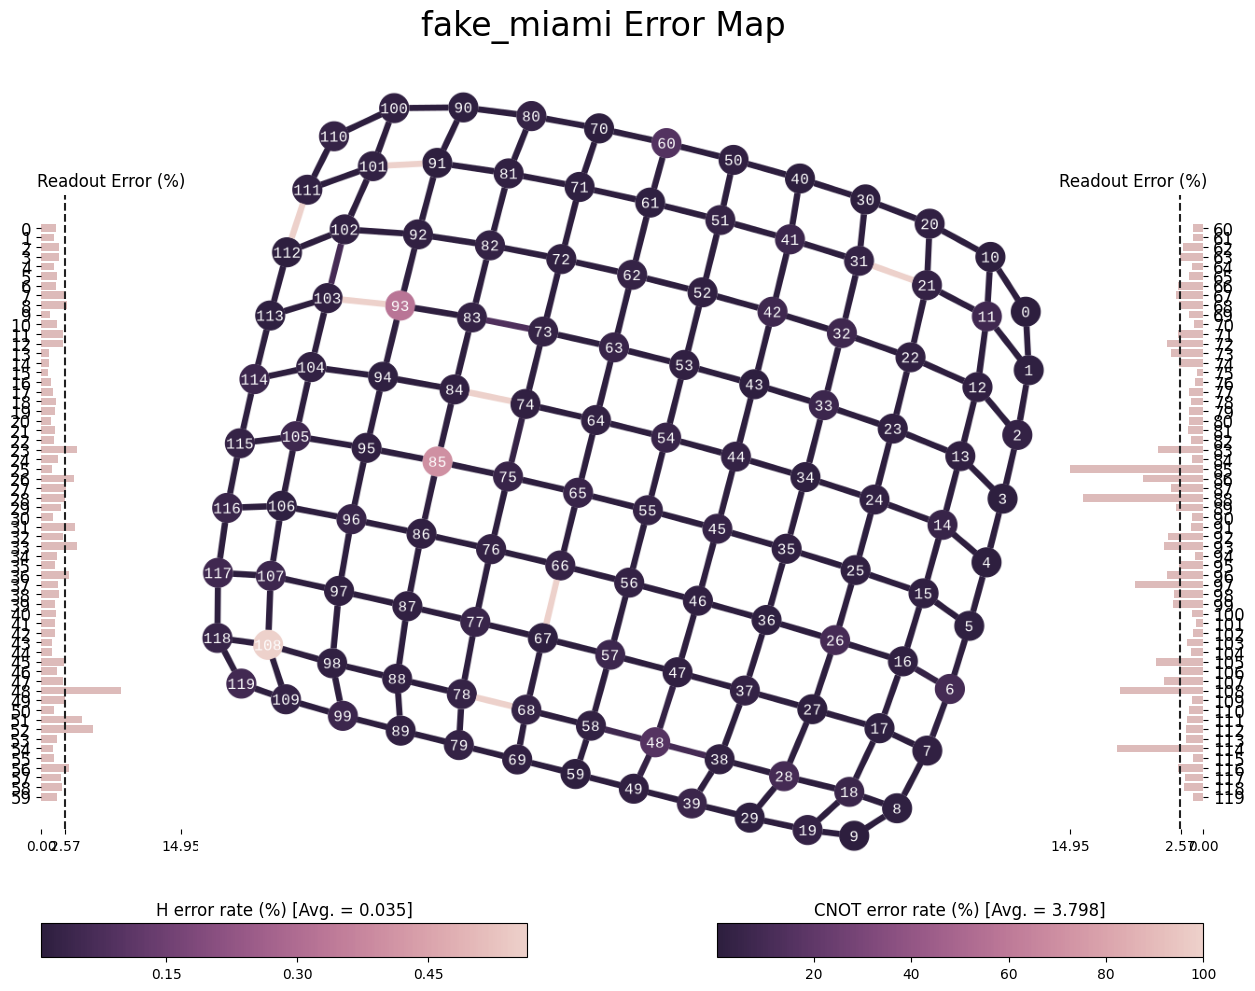

In [ ]:
from qiskit_ibm_runtime.fake_provider import FakeMiami
from qiskit.visualization import plot_error_map

# Use the fake backend because ibm_miami is unavailable to this account
backend_nh = FakeMiami()

plot_error_map(backend_nh)

In [ ]:
backend_nh = service.backend("ibm_miami")
# Use this command to use FakeMiami if you don't have access to ibm_miami
backend_nh = FakeMiami()

plot_error_map(backend_nh)

<a id="exercise_1a"></a>
<div class="alert alert-block alert-success">

<b>Exercise 1a: Select the alpha–beta interaction pairs for the Nighthawk device</b>

**Your Goal:** Fill `alpha_beta_indices_nh` with the cross-spin interaction pairs appropriate for the Nighthawk device topology.

**Background:** Recall from Section 2 that each `(p, q)` tuple in `alpha_beta_indices` means "the Jastrow factor couples α-orbital $p$ to β-orbital $q$, and those two qubits must be physically adjacent on the chip."

- On **Heron (`ibm_kingston`)**, the α and β qubit chains only touch at every 4th site, so we used `[(p, p) for p in range(0, num_orbitals, 4)]` truncated to 5 pairs (there are only 5 hardware-adjacent α–β crossings).
- On **Nighthawk (`ibm_miami`)**, the α and β rails can be laid next to each other so that $p$-th qubit on the α chain can interact with the $p$-th qubit on the β chain for *every* $p$. There is no need to skip indices.

**Hint:**
- **(Recommended)** You can make 24 qubit pairs (truncate at 24) rather than pairing the entire qubits. This is to make it easier to map this to the Nighthawk topology.
- You may notice that you cannot arrange every α and β pair side-by-side, but don't worry about that at this stage.

</div>

In [ ]:
# Select alpha-beta interaction pairs according to the Nighthawk device topology
# ---- TODO : Task 1a ----
alpha_beta_indices_nh = [(p, p) for p in range(24)]
# ---- End of TODO : Task 1a ----

print(alpha_beta_indices_nh)

[(0, 0), (1, 1), (2, 2), (3, 3), (4, 4), (5, 5), (6, 6), (7, 7), (8, 8), (9, 9), (10, 10), (11, 11), (12, 12), (13, 13), (14, 14), (15, 15), (16, 16), (17, 17), (18, 18), (19, 19), (20, 20), (21, 21), (22, 22), (23, 23)]


In [ ]:
grade_lab4c_ex1a(alpha_beta_indices_nh)

Grading your answer. Please wait...

Congratulations! 🎉 Your answer is correct.
You scored 1 on this exercise.




In [ ]:
n_reps = 1
ucj_op_nh = ffsim.UCJOpSpinBalanced.from_t_amplitudes(
    t1=t1,
    t2=t2,
    n_reps=n_reps,
    interaction_pairs=(alpha_alpha_indices, alpha_beta_indices_nh),
    optimize=True,
    options=dict(maxiter=20),
)
nelec = (num_elec_a, num_elec_b)

# create an empty quantum circuit
qubits = QuantumRegister(2 * num_orbitals, name="q")
circuit_nh = QuantumCircuit(qubits)

# prepare Hartree-Fock state as the reference state and append it to the quantum circuit
circuit_nh.append(ffsim.qiskit.PrepareHartreeFockJW(num_orbitals, nelec), qubits)

# apply the UCJ operator to the reference state
circuit_nh.append(ffsim.qiskit.UCJOpSpinBalancedJW(ucj_op_nh), qubits)

# investigate the circuit for execution
inner_circuit_nh = ffsim.qiskit.PRE_INIT.run(circuit_nh)
for i in range(2, 0, -1):
    inner_circuit_nh.data.insert(i, CircuitInstruction(Barrier(num_qubits=2*num_orbitals), qubits))
display(inner_circuit_nh.decompose().draw("mpl", fold=-1))

# insert final measurement
circuit_nh.measure_all()

<a id="exercise_1b"></a>
<div class="alert alert-block alert-success">

<b>Exercise 1b: Define the qubit layout for the Nighthawk device</b>

**Your Goal:** Provide `spin_a_layout` and `spin_b_layout` — lists of exactly `num_orbitals` (= 26) physical qubit indices each — that correctly map the α and β spin-orbital chains onto Nighthawk's hardware.

**Background:** `initial_layout` instructs the transpiler to place logical qubit $p$ on physical qubit `initial_layout[p]`. A good layout must satisfy two requirements simultaneously:

1. **Connectivity within each spin sector:** the same-spin nearest-neighbor interactions `alpha_alpha_indices = [(p, p+1) ...]` require physical qubits $p$ and $p+1$ within each list to be hardware-adjacent (connected by a two-qubit gate line on the chip). Each list should therefore trace a *connected path* through the device graph.

2. **α–β adjacency:** according to the pairs provided in exercise 1a, locate the pairs close to each other as much as possible. This time, it is fine to use a few swaps if needed.

**Hint:**
- Every α and β pair may not sit side-by-side. Applying a few swap operations is fine, as long as the swaps can operate in parallel, keeping the circuit depth minimal.
- **(Optional)** If you want to try a more advanced challenge, you can try pairing every 26 qubits in the previous exercise and map them to the Nighthawk. The passing criteria is quite challenging and the grader result may fluctuate according to the transpiler seed. You can make a few trials to get a better transpilation result.
</div>

In [ ]:
# select spin a and b layout according to the device topology
# ---- TODO : Task 1b ----
# select spin a and b layout according to the device topology
# ---- TODO : Task 1b ----

spin_a_layout = [
      1,  11,  21,  31,  41,  51,  61,  71,  81,  91,
    101, 102,  92,  93, 103, 104, 105, 106, 107, 108,
     98,  97,  87,  88,  78,  68,
]

spin_b_layout = [
      0,  10,  20,  30,  40,  50,  60,  70,  80,  90,
    100, 110, 111, 112, 113, 114, 115, 116, 117, 118,
    119, 109,  99,  89,  79,  69,
]

initial_layout = spin_a_layout + spin_b_layout

# ---- End of TODO : Task 1b ----
# ---- End of TODO : Task 1b ----

initial_layout = spin_a_layout + spin_b_layout

pass_manager = generate_preset_pass_manager(
    optimization_level=3, backend=backend_nh, initial_layout=initial_layout
)

# without PRE_INIT passes
isa_circuit_nh = pass_manager.run(circuit_nh)
print(f"Gate counts (w/o pre-init passes): {isa_circuit_nh.count_ops()}")

# with PRE_INIT passes
# We will use the circuit generated by this pass manager for hardware execution
pass_manager.pre_init = ffsim.qiskit.PRE_INIT
isa_circuit_nh = pass_manager.run(circuit_nh)
print(f"Gate counts (w/ pre-init passes): {isa_circuit_nh.count_ops()}")

Gate counts (w/o pre-init passes): OrderedDict({'sx': 11664, 'rz': 11625, 'cz': 3492, 'x': 403, 'measure': 52, 'barrier': 1})
Gate counts (w/ pre-init passes): OrderedDict({'sx': 6998, 'rz': 6946, 'cz': 1834, 'measure': 52, 'x': 50, 'barrier': 1})


In [ ]:
grade_lab4c_ex1b(initial_layout, alpha_beta_indices_nh, seed=None)

Grading your answer. Please wait...

Congratulations! 🎉 Your answer is correct.
You scored 1 on this exercise.


## 3. Quantum Sampling

With the circuit mapped to Nighthawk's topology, we submit 2,000 shots to the device.
Each **shot** measures all `2*num_orbitals` qubits and returns one **bitstring** — a binary snapshot of which orbitals are occupied at that moment.
Physically, each bitstring is *one proposed electron configuration*: a candidate for a basis state of the ground state.

The collection of all 2,000 bitstrings, together with how often each distinct configuration appears, is the raw material that SQD will process.

> **Note on runtime:** Running a real hardware job takes 10 seconds on `ibm_miami` or 2 seconds on `ibm_kingston`.
> To keep this notebook self-contained, the cell below submits the job and saves the `job_id`.
> The *following* cell retrieves the pre-computed results from that saved ID — you do not need to resubmit.

In [ ]:
# Option 1: if you have an access to the Nighthawk device, try running the square-lattice circuit.
#sampler = Sampler(mode=backend_nh)
#job = sampler.run([isa_circuit_nh], shots=2_000)
# Option 2: if you don't have an access to the Nighthawk device, you can run Heron fitted circuit.
sampler = Sampler(mode=backend_hr)
job = sampler.run([isa_circuit_hr], shots=2_000)
job_id = job.job_id()
print(f"Submitted job {job_id}")

The cell below retrieves the completed job and converts the raw measurement outcomes into two arrays:

- `raw_bitstrings` — integer array of shape `(n_unique, 2*num_orbitals)` where each row is a distinct bitstring (each element is 0 or 1).
- `raw_probs` — float array of length `n_unique` giving the empirical probability of each bitstring; `raw_probs[k]` is the fraction of shots that produced `raw_bitstrings[k]`.

In [ ]:
primitive_result = job.result()
pub_result = primitive_result[0]
bit_array = pub_result.data.meas

raw_bitstrings, raw_probs = bit_array_to_arrays(bit_array)

print("Shape:", raw_bitstrings.shape)
print("First bitstring:", raw_bitstrings[0])

Shape: (2000, 52)
First bitstring: [False False False False False False False False False  True  True False
 False  True  True  True False  True  True False  True  True False  True
  True False  True  True False False False  True False False False False
  True False False False False False False  True  True  True False  True
 False False  True False]


In [ ]:
def reshape_bitstring(
    bitstrings: np.ndarray,
    num_orbitals: int
) -> np.ndarray:

    reshaped_bitstrings = bitstrings.reshape(
        -1,
        2,
        num_orbitals
    )

    # Qiskit output places the beta block before the alpha block
    reshaped_bitstrings = reshaped_bitstrings[:, ::-1, :]

    return reshaped_bitstrings


reshaped_bitstrings = reshape_bitstring(
    raw_bitstrings,
    num_orbitals
)

print("Reshaped shape:", reshaped_bitstrings.shape)
print("First sample:")
print(reshaped_bitstrings[0])

Reshaped shape: (2000, 2, 26)
First sample:
[[ True  True False False False  True False False False False  True False
  False False False False False  True  True  True False  True False False
   True False]
 [False False False False False False False False False  True  True False
  False  True  True  True False  True  True False  True  True False  True
   True False]]


In [ ]:
# Retrieve job using the job id
job_id = "<YOUR_JOB_ID>"
job = service.job(job_id)
primitive_result = job.result()
pub_result = primitive_result[0]
bit_array = pub_result.data.meas

# Convert BitArray into bitstring and probability arrays
raw_bitstrings, raw_probs = bit_array_to_arrays(bit_array)

## Exercise 2: Examine the resulting bitstrings

Once the sampling is done, it's time to understand what we have.
The two code cells below let you inspect the shape and contents of `raw_bitstrings` before you begin processing.
Run them first, then complete the two exercises.

In [ ]:
print(raw_bitstrings.shape)

(2000, 52)


In [ ]:
print(raw_bitstrings[0])

[False False False False False False False False False  True  True False
 False  True  True  True False  True  True False  True  True False  True
  True False  True  True False False False  True False False False False
  True False False False False False False  True  True  True False  True
 False False  True False]


<a id="exercise_2a"></a>
<div class="alert alert-block alert-success">

<b>Exercise 2a: Reshape the raw bitstrings into spin sectors</b>

**Your Goal:** Implement `reshape_bitstring` to divide the **spin-α** and **spin-β** bitstrings from the experiment results.

**Background:** The Jordan–Wigner encoding places the spin-α qubits in the *first* block of each bitstring and the spin-β qubits in the *second* block.
A `1` at position $p$ in the α block means "α-orbital $p$ is occupied"; `0` means empty.  
Separating the two spin sectors lets us:
- Check the electron count per spin independently (Exercise 2b).
- Apply spin-specific corrections during configuration recovery (Exercise 3).

**Hint:**
- The shape of the `raw_bitstrings` is **(2000, 52)**. You should get an array of shape **(2000, 2, 26)**.
- **Bit-ordering caution:** Qiskit returns measurement results in *little-endian* (last qubit measured = first bit in string). After reshaping, verify which block is α by printing `reshaped_bitstrings[0, :]` and checking whether the block matches with the α bitstring. You may need to flip the spin-block ordering so that index 0 is always α.
- Cross-check with the raw `raw_bitstrings[0]` printed above.

</div>

In [ ]:
def reshape_bitstring(
    bitstrings: np.ndarray,
    num_orbitals: int
) -> np.ndarray:

    # ---- TODO : Task 2a ----
    reshaped_bitstrings = bitstrings.reshape(-1, 2, num_orbitals)
    # ---- End of TODO : Task 2a ----

    return reshaped_bitstrings


print(reshaped_bitstrings[0, :])

[[False False False False False False False False False  True  True False
  False  True  True  True False  True  True False  True  True False  True
   True False]
 [ True  True False False False  True False False False False  True False
  False False False False False  True  True  True False  True False False
   True False]]


In [ ]:
def reshape_bitstring(
    bitstrings: np.ndarray,
    num_orbitals: int
) -> np.ndarray:

    # ---- TODO : Task 2a ----
    reshaped_bitstrings = bitstrings.reshape(
        bitstrings.shape[0],
        2,
        num_orbitals
    )
    # ---- End of TODO : Task 2a ----

    return reshaped_bitstrings

In [ ]:
reshaped_bitstrings = reshape_bitstring(
    raw_bitstrings,
    num_orbitals
)

print("Shape:", reshaped_bitstrings.shape)
print("Alpha:", reshaped_bitstrings[0, 0])
print("Beta: ", reshaped_bitstrings[0, 1])

Shape: (2000, 2, 26)
Alpha: [False False False False False False False False False  True  True False
 False  True  True  True False  True  True False  True  True False  True
  True False]
Beta:  [ True  True False False False  True False False False False  True False
 False False False False False  True  True  True False  True False False
  True False]


In [ ]:
def reshape_bitstring(
    bitstrings: np.ndarray,
    num_orbitals: int
) -> np.ndarray:

    # ---- TODO : Task 2a ----
    beta_bitstrings = bitstrings[:, :num_orbitals]
    alpha_bitstrings = bitstrings[:, num_orbitals:]

    reshaped_bitstrings = np.stack(
        (alpha_bitstrings, beta_bitstrings),
        axis=1
    )
    # ---- End of TODO : Task 2a ----

    return reshaped_bitstrings

In [ ]:
reshaped_bitstrings = reshape_bitstring(
    raw_bitstrings,
    num_orbitals
)

print("Shape:", reshaped_bitstrings.shape)
print("Alpha:", reshaped_bitstrings[0, 0])
print("Beta: ", reshaped_bitstrings[0, 1])

Shape: (2000, 2, 26)
Alpha: [False False False False False False False False False  True  True False
 False  True  True  True False  True  True False  True  True False  True
  True False]
Beta:  [ True  True False False False  True False False False False  True False
 False False False False False  True  True  True False  True False False
  True False]


In [ ]:
test_bits = np.array(
    [[1, 1, 1, 1, 1, 1,
      0, 0, 0, 0, 0, 0]],
    dtype=bool
)

test_result = reshape_bitstring(test_bits, 6)

print("Test alpha:", test_result[0, 0])
print("Test beta: ", test_result[0, 1])

Test alpha: [ True  True  True  True  True  True]
Test beta:  [False False False False False False]


In [ ]:
def reshape_bitstring(
    bitstrings: np.ndarray,
    num_orbitals: int
) -> np.ndarray:

    # ---- TODO : Task 2a ----
    reshaped_bitstrings = bitstrings.reshape(
        bitstrings.shape[0],
        2,
        num_orbitals
    )

    # Raw order is (beta, alpha); return (alpha, beta)
    reshaped_bitstrings = reshaped_bitstrings[:, [1, 0], :]
    # ---- End of TODO : Task 2a ----

    return reshaped_bitstrings

In [ ]:
test_bits = np.array(
    [[1, 1, 1, 1, 1, 1,
      0, 0, 0, 0, 0, 0]],
    dtype=bool
)

test_result = reshape_bitstring(test_bits, 6)

print("Test alpha:", test_result[0, 0])
print("Test beta: ", test_result[0, 1])

Test alpha: [False False False False False False]
Test beta:  [ True  True  True  True  True  True]


In [ ]:
reshaped_bitstrings = reshape_bitstring(
    raw_bitstrings,
    num_orbitals
)

print("Shape:", reshaped_bitstrings.shape)
print("Alpha:", reshaped_bitstrings[0, 0])
print("Beta: ", reshaped_bitstrings[0, 1])

grade_lab4c_ex2a(
    reshape_bitstring,
    raw_bitstrings
)

Shape: (2000, 2, 26)
Alpha: [ True  True False False False  True False False False False  True False
 False False False False False  True  True  True False  True False False
  True False]
Beta:  [False False False False False False False False False  True  True False
 False  True  True  True False  True  True False  True  True False  True
  True False]
Grading your answer. Please wait...

Congratulations! 🎉 Your answer is correct.
You scored 1 on this exercise.


In [ ]:
grade_lab4c_ex2a(reshape_bitstring, raw_bitstrings)

Grading your answer. Please wait...

Congratulations! 🎉 Your answer is correct.
You scored 1 on this exercise.


<a id="exercise_2b"></a>
<div class="alert alert-block alert-success">

<b>Exercise 2b: Count electrons per sample (Hamming weight)</b>

**Your Goal:** Implement `hamming_weight` that takes the reshaped bitstring array and returns an integer array giving the number of occupied orbitals for each spin sector in each sample.

**Background:** The **Hamming weight** of a binary string is simply its number of 1s.
In our context, Hamming weight = number of electrons of that spin in that sample.

A *valid* sample must have exactly 5 spin-α electrons **and** 5 spin-β electrons (particle number conservation).
In a noiseless world, every shot would be valid. On real hardware, bit-flip errors and other noise mechanisms push some bitstrings outside the correct particle-number sector — those samples are physically meaningless and would corrupt the diagonalization if used directly.

Counting the Hamming weight is the first step to detecting these bad samples.

**Hint:** Sum over the last axis (the orbital axis).

</div>

In [ ]:
def hamming_weight(bitstrings: np.ndarray) -> np.ndarray:

    # ---- TODO : Task 2b ----
    weight = bitstrings.sum(axis=-1)
    # ---- End of TODO : Task 2b ----

    return weight


print(hamming_weight(reshaped_bitstrings)[0])

[ 9 11]


In [ ]:
grade_lab4c_ex2b(hamming_weight)

Grading your answer. Please wait...

Congratulations! 🎉 Your answer is correct.
You scored 1 on this exercise.


The cell below checks how many samples already have the correct electron counts — i.e., how many shots are "valid" before any repair. Never be surprised by finding an outcome `0` :)

In [ ]:
print(int(2e3*np.sum(raw_probs[np.all(hamming_weight(reshaped_bitstrings) == nelec)])))

0


## Exercise 3: Recover the bitstring

### Why configuration recovery is necessary

The true molecular ground state lives entirely within the **fixed-particle-number sector**: configurations with exactly `(num_elec_a, num_elec_b)` electrons.
Quantum mechanics conserves particle number — the physical molecule cannot spontaneously gain or lose electrons.

However, a real quantum device introduces **bit-flip errors** (and other noise) that change some `0`s to `1`s and vice versa.
A single bit-flip moves a bitstring *out* of the physical sector; suddenly, the sample reports the wrong number of electrons.
That sample is physically meaningless and, if fed directly to the diagonalizer, would contaminate the subspace with non-physical configurations.

**Configuration recovery** repairs each broken sample by flipping the minimum number of bits needed to restore the correct electron count, choosing *which* bits to flip based on our current best estimate of each orbital's average occupancy.

### Initializing occupancy from Hartree–Fock

The recovery algorithm needs a prior estimate of "how occupied is each orbital, on average?"
We bootstrap this with the **Hartree–Fock occupancy**: the `num_elec_a` highest-index orbitals are fully occupied (occupancy = 1), the rest are empty (occupancy = 0).
As the SQD loop progresses, this is replaced by the actual orbital occupancies measured from the diagonalized quantum state — so the recovery improves with each iteration.

In [ ]:
initial_occupancy = np.zeros((2, num_orbitals), dtype=float)
initial_occupancy[:, -num_elec_a:] = 1.
print(initial_occupancy)

[[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 1. 1.
  1. 1.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 1. 1.
  1. 1.]]


<a id="exercise_3a"></a>
<div class="alert alert-block alert-success">

<b>Exercise 3a: Define the bit-flip probability function</b>

**Your Goal:** Implement `weight_flip_0_to_1(occupancy)` which, given an array of orbital occupancies in $[0, 1]$, returns the probability weight for flipping each orbital from empty (0) to occupied (1).

**Background:** When a sample is *missing* an electron (too few 1s), we must flip some empty orbital to occupied.
We want to preferentially fill orbitals that are *usually* occupied — because the true ground state probably has those orbitals filled.
Conversely, we should almost never fill an orbital that is usually empty.

The function:

$$W_{0\to1}(\text{occ}) = e^{\text{occ}} - 1, \qquad 0 \le \text{occ} \le 1$$

has a kind of that behavior:
- $W_{0\to1}(0) = 0$ — never fill a never-occupied orbital.
- $W_{0\to1}(1) = e - 1 \approx 1.718$ — strongly prefer filling an always-occupied orbital.
- Monotonically increasing in between.

The companion function `weight_flip_1_to_0(occ) = weight_flip_0_to_1(1 - occ)` is already provided; removing an electron favors orbitals that are usually empty (high probability of being 0).

</div>

In [ ]:
def weight_flip_0_to_1(occupancy: np.ndarray) -> np.ndarray:

    # ---- TODO : Task 3a ----
def weight_flip_0_to_1(occupancy: np.ndarray) -> np.ndarray:
return np.exp(occupancy) - 1.0

def weight_flip_1_to_0(occupancy):
return weight_flip_0_to_1(1 - occupancy)
    # ---- End of TODO : Task 3a ----

    return prob

def weight_flip_1_to_0(occupancy):
    return weight_flip_0_to_1(1-occupancy)

In [ ]:
def weight_flip_0_to_1(occupancy: np.ndarray) -> np.ndarray:

    # ---- TODO : Task 3a ----
    prob = np.exp(occupancy) - 1.0
    # ---- End of TODO : Task 3a ----

    return prob


def weight_flip_1_to_0(occupancy: np.ndarray) -> np.ndarray:
    return weight_flip_0_to_1(1 - occupancy)

In [ ]:
test_occupancy = np.array([0.0, 0.25, 0.5, 0.75, 1.0])

print("0 -> 1:", weight_flip_0_to_1(test_occupancy))
print("1 -> 0:", weight_flip_1_to_0(test_occupancy))

0 -> 1: [0.         0.28402542 0.64872127 1.11700002 1.71828183]
1 -> 0: [1.71828183 1.11700002 0.64872127 0.28402542 0.        ]


In [ ]:
grade_lab4c_ex3a(weight_flip_0_to_1)

Grading your answer. Please wait...

Congratulations! 🎉 Your answer is correct.
You scored 1 on this exercise.


<a id="exercise_3b"></a>
<div class="alert alert-block alert-success">

<b>Exercise 3b: Recover bitstring configurations to the correct electron count</b>

**Your Goal:** Complete the `recover_configurations` function by filling in the three-branch correction logic inside the per-spin loop.

**Background — the algorithm, step by step:**

The outer loop iterates over every bitstring sample. For each sample and each spin sector `i` (0 = α, 1 = β):

1. Compute `weight[i]` = Hamming weight = number of electrons in sector `i` (you wrote this in Exercise 2b).
2. Compare `weight[i]` to `num_elec[i]`:

   - **Too few electrons** (`weight[i] < num_elec[i]`): we must flip `num_elec[i] - weight[i]` empty bits to 1.
     - Find empty orbitals
     - Get flip weights for those candidates
     - Normalize the weights to make a probability distribution
     - Randomly select which to flip
     - Set the chosen bits to `True`

   - **Too many electrons** (`weight[i] > num_elec[i]`): we must flip `weight[i] - num_elec[i]` occupied bits to 0.
     - Mirror the procedure above, but make sure that you are choosing occupied bits to flip.

   - **Exactly right** (`weight[i] == num_elec[i]`): leave the spin sector unchanged.

**Hint:** Each branch needs four lines: find candidates with `np.where`, compute and normalize probabilities, call `rand_seed.choice` to choose which bit to flip, and flip the bits.

**Note:** The output format: each corrected bitstring is converted to a string and accumulated into `corrected_dict` (a `defaultdict` that merges any bitstrings that end up identical after correction).

</div>

In [ ]:
def recover_configurations(
    bitstrings: np.ndarray,
    probs: np.ndarray,
    occupancy: np.ndarray,
    num_orbitals: int,
    num_elec: tuple[int, int],
    rand_seed: np.random.Generator,
) -> tuple[np.ndarray, np.ndarray]:
    corrected_dict: defaultdict[str, float] = defaultdict(float)
    for bitstring, freq, weight in zip(bitstrings, probs, hamming_weight(bitstrings)):
        bs_corrected = bitstring.copy()
        for i in range(2):
            # ---- TODO : Task 3b ----

def recover_configurations(
    bitstrings: np.ndarray,
    probs: np.ndarray,
    occupancy: np.ndarray,
    num_orbitals: int,
    num_elec: tuple[int, int],
    rand_seed: np.random.Generator,
) -> tuple[np.ndarray, np.ndarray]:
    corrected_dict: defaultdict[str, float] = defaultdict(float)
for bitstring, freq, weight in zip(bitstrings, probs, hamming_weight(bitstrings)):
        bs_corrected = bitstring.copy()
        for i in range(2):
            # ---- TODO : Task 3b ----
            if weight[i] < num_elec[i]:
                # Too few electrons: flip some 0s to 1s
                zeros = np.where(bs_corrected[i] == 0)[0]
                if len(zeros) == 0:
                    continue
                # Probability of flipping each zero to 1
                flip_probs = weight_flip_0_to_1(occupancy[i][zeros])
                flip_probs = flip_probs / flip_probs.sum()
                # Choose which zeros to flip
                n_flip = num_elec[i] - weight[i]
                chosen = rand_seed.choice(zeros, size=n_flip, replace=False, p=flip_probs)
                bs_corrected[i][chosen] = 1
            elif weight[i] > num_elec[i]:
                # Too many electrons: flip some 1s to 0s
                ones = np.where(bs_corrected[i] == 1)[0]
                if len(ones) == 0:
                    continue
                flip_probs = weight_flip_1_to_0(occupancy[i][ones])
                flip_probs = flip_probs / flip_probs.sum()
                n_flip = weight[i] - num_elec[i]
                chosen = rand_seed.choice(ones, size=n_flip, replace=False, p=flip_probs)
                bs_corrected[i][chosen] = 0
            # else: correct count, do nothing
            # ---- End of TODO : Task 3b ----
        bs_str = "".join("1" if bit else "0" for bit in bs_corrected.flatten())
        corrected_dict[bs_str] += freq

    bs_mat_out = np.array([[bit == "1" for bit in bs] for bs in corrected_dict]).reshape(-1, 2, num_orbitals)
    freqs_out = np.array([f for f in corrected_dict.values()])
    freqs_out = np.abs(freqs_out) / np.sum(np.abs(freqs_out))

    return bs_mat_out, freqs_out


            # ---- End of TODO : Task 3b ----
        bs_str = "".join("1" if bit else "0" for bit in bs_corrected.flatten())
        corrected_dict[bs_str] += freq

    bs_mat_out = np.array([[bit == "1" for bit in bs] for bs in corrected_dict]).reshape(-1, 2, num_orbitals)
    freqs_out = np.array([f for f in corrected_dict.values()])
    freqs_out = np.abs(freqs_out) / np.sum(np.abs(freqs_out))

    return bs_mat_out, freqs_out

recovered_bitstrings, recovered_probs = recover_configurations(
    reshaped_bitstrings, raw_probs, initial_occupancy, num_orbitals, nelec, np.random.default_rng())

In [ ]:
import numpy as np
from collections import defaultdict


# ============================================================
# Task 2a: Reshape bitstrings into (alpha, beta) sectors
# ============================================================

def reshape_bitstring(
    bitstrings: np.ndarray,
    num_orbitals: int,
) -> np.ndarray:

    # Raw measurement order is (beta, alpha).
    reshaped_bitstrings = bitstrings.reshape(
        bitstrings.shape[0],
        2,
        num_orbitals,
    )

    # Exchange the two blocks so the output order is (alpha, beta).
    reshaped_bitstrings = reshaped_bitstrings[:, [1, 0], :]

    return reshaped_bitstrings


# Recreate the real reshaped bitstrings.
reshaped_bitstrings = reshape_bitstring(
    raw_bitstrings,
    num_orbitals,
)

print("Reshaped bitstrings shape:", reshaped_bitstrings.shape)
print("First alpha bitstring:", reshaped_bitstrings[0, 0])
print("First beta bitstring: ", reshaped_bitstrings[0, 1])


# ============================================================
# Task 2b: Calculate Hamming weights
# ============================================================

def hamming_weight(bitstrings: np.ndarray) -> np.ndarray:

    # Count the number of occupied orbitals in each spin sector.
    weight = bitstrings.sum(axis=-1)

    return weight


print(
    "First sample electron counts (alpha, beta):",
    hamming_weight(reshaped_bitstrings)[0],
)


# ============================================================
# Task 3a: Bit-flip probability weights
# ============================================================

def weight_flip_0_to_1(
    occupancy: np.ndarray,
) -> np.ndarray:

    prob = np.exp(occupancy) - 1.0

    return prob


def weight_flip_1_to_0(
    occupancy: np.ndarray,
) -> np.ndarray:

    return weight_flip_0_to_1(1.0 - occupancy)


# ============================================================
# Task 3b: Recover configurations
# ============================================================

def recover_configurations(
    bitstrings: np.ndarray,
    probs: np.ndarray,
    occupancy: np.ndarray,
    num_orbitals: int,
    num_elec: tuple[int, int],
    rand_seed: np.random.Generator,
) -> tuple[np.ndarray, np.ndarray]:

    corrected_dict: defaultdict[str, float] = defaultdict(float)

    # Electron counts for every sample and spin sector.
    all_weights = hamming_weight(bitstrings)

    for bitstring, freq, weight in zip(
        bitstrings,
        probs,
        all_weights,
    ):
        # Avoid changing the original input array.
        bs_corrected = bitstring.copy()

        # i = 0 means alpha, i = 1 means beta.
        for i in range(2):

            # ------------------------------------------------
            # Too few electrons: flip selected zeros to ones.
            # ------------------------------------------------
            if weight[i] < num_elec[i]:

                candidates = np.where(
                    bs_corrected[i] == 0
                )[0]

                flip_probs = weight_flip_0_to_1(
                    occupancy[i, candidates]
                )

                # Normally the sum is nonzero. The fallback makes
                # the function safe for unusual occupancy arrays.
                if np.isclose(flip_probs.sum(), 0.0):
                    flip_probs = np.ones(
                        len(candidates),
                        dtype=float,
                    )

                flip_probs = flip_probs / flip_probs.sum()

                number_to_flip = (
                    num_elec[i] - int(weight[i])
                )

                chosen = rand_seed.choice(
                    candidates,
                    size=number_to_flip,
                    replace=False,
                    p=flip_probs,
                )

                bs_corrected[i, chosen] = True

            # ------------------------------------------------
            # Too many electrons: flip selected ones to zeros.
            # ------------------------------------------------
            elif weight[i] > num_elec[i]:

                candidates = np.where(
                    bs_corrected[i] == 1
                )[0]

                flip_probs = weight_flip_1_to_0(
                    occupancy[i, candidates]
                )

                if np.isclose(flip_probs.sum(), 0.0):
                    flip_probs = np.ones(
                        len(candidates),
                        dtype=float,
                    )

                flip_probs = flip_probs / flip_probs.sum()

                number_to_flip = (
                    int(weight[i]) - num_elec[i]
                )

                chosen = rand_seed.choice(
                    candidates,
                    size=number_to_flip,
                    replace=False,
                    p=flip_probs,
                )

                bs_corrected[i, chosen] = False

            # When weight[i] == num_elec[i], no change is needed.

        # Convert the corrected alpha-beta array into one string.
        bs_str = "".join(
            "1" if bit else "0"
            for bit in bs_corrected.flatten()
        )

        # Combine probabilities for identical corrected strings.
        corrected_dict[bs_str] += float(freq)

    # Convert corrected strings back into Boolean arrays.
    bs_mat_out = np.array(
        [
            [bit == "1" for bit in bitstring]
            for bitstring in corrected_dict
        ],
        dtype=bool,
    ).reshape(
        -1,
        2,
        num_orbitals,
    )

    # Extract and normalize the corrected probabilities.
    freqs_out = np.array(
        list(corrected_dict.values()),
        dtype=float,
    )

    freqs_out = np.abs(freqs_out)
    freqs_out = freqs_out / freqs_out.sum()

    return bs_mat_out, freqs_out


# ============================================================
# Run configuration recovery
# ============================================================

rng = np.random.default_rng(42)

recovered_bitstrings, recovered_probs = recover_configurations(
    reshaped_bitstrings,
    raw_probs,
    initial_occupancy,
    num_orbitals,
    nelec,
    rng,
)


# ============================================================
# Verify the output
# ============================================================

recovered_weights = hamming_weight(
    recovered_bitstrings
)

print("\nRecovered bitstrings shape:", recovered_bitstrings.shape)
print("Recovered probabilities shape:", recovered_probs.shape)
print("Probability sum:", recovered_probs.sum())

print(
    "First recovered electron counts:",
    recovered_weights[0],
)

print(
    "All recovered configurations valid:",
    np.all(
        recovered_weights
        == np.asarray(nelec)
    ),
)

Reshaped bitstrings shape: (2000, 2, 26)
First alpha bitstring: [ True  True False False False  True False False False False  True False
 False False False False False  True  True  True False  True False False
  True False]
First beta bitstring:  [False False False False False False False False False  True  True False
 False  True  True  True False  True  True False  True  True False  True
  True False]
First sample electron counts (alpha, beta): [ 9 11]

Recovered bitstrings shape: (1997, 2, 26)
Recovered probabilities shape: (1997,)
Probability sum: 0.9999999999999993
First recovered electron counts: [5 5]
All recovered configurations valid: True


The cell below shows how many samples are valid (correct electron count) **after** configuration recovery — compare to the pre-recovery number from Exercise 2b.

In [ ]:
print(np.rint(2e3*np.sum(recovered_probs[np.all(hamming_weight(recovered_bitstrings) == nelec, axis=1)])).astype(int))

2000


In [ ]:
grade_lab4c_ex3b(recover_configurations)

Grading your answer. Please wait...

Congratulations! 🎉 Your answer is correct.
You scored 1 on this exercise.


### From recovered bitstrings to the diagonalization subspace

With all samples now in the correct particle-number sector, we prepare them for diagonalization:

1. **`subsample`** splits the recovered configurations into `num_batches` independent batches of `samples_per_batch` samples each. Running the eigensolver on multiple independent batches gives us variance estimates (the box plot later shows the spread) and reduces the chance of getting stuck in an unlucky set of configurations.

2. **`bitstring_matrix_to_integers`** packs each binary bitstring into a single Python integer — the standard "determinant label" format that the selected-CI eigensolver `solve_sci_batch` expects. These integer labels, called **CI strings**, identify each electron configuration (Slater determinant) uniquely.

3. **`build_subspace`** takes the CI strings, deduplicates within each batch, sorts by marginal probability (most-sampled first), optionally prepends a user-specified `include` set, and truncates to `max_dim` configurations per spin. The result is the **subspace basis**: the set of Slater determinants the Hamiltonian will be projected onto.

In [ ]:
subsamples = np.array(subsample(recovered_bitstrings.reshape(-1, 2*num_orbitals), recovered_probs, samples_per_batch=20, num_batches=5))
subsamples = subsamples.reshape(*subsamples.shape[:-1], 2, -1)
print(subsamples.shape)
print(subsamples[4, 19])

(5, 20, 2, 26)
[[False False False False False  True False False False False False False
  False  True False False False False  True False False False  True False
   True False]
 [False False False  True False False False False False False False False
  False False False  True False False False False False  True  True  True
  False False]]


In [ ]:
ci_strs = np.array([bitstring_matrix_to_integers(samples[:, i]) for samples in subsamples for i in range(2)])
ci_strs = ci_strs.reshape(-1, 2, ci_strs.shape[-1])
print(ci_strs.shape)
print(ci_strs[0])

(5, 2, 20)
[[      91 33587331      342     5284  1064998 37749016 16812044    12833
      3203       47  8716808   131342  1048603   137240 33571858 16781323
     74113  2097167   270343 12845065]
 [ 1073218   542852     1051    16462    98323     1053  2626576 42074372
     65619   263187   787468       31 37748785   393734   262174 16777396
  33816597   557580   270355 33816598]]


In [ ]:
def build_subspace(subsamples, include=np.empty((2, 0), dtype=int), max_dim=(None, None)):

    subspaces = []
    for samples in subsamples:
        subspace_list = []
        for i in range(2):

            # Get the single-spin bitstrings and counts.
            bitstrings, counts = np.unique(samples[i], return_counts=True)

            # Sort the single-spin bitstrings in descending order by marginal probability.
            bitstrings = bitstrings[np.argsort(counts)[::-1]]
            
            # Prioritize explicitly requested bitstrings, then sampled bitstrings
            subspace = np.concatenate((include[i], bitstrings))

            # Get unique values while preserving the original order
            _, indices = np.unique(subspace, return_index=True)
            indices.sort()
            subspace = subspace[indices]

            # Truncate bitstrings to the maximum dimension.
            subspace = subspace[:max_dim[i]]
            subspace.sort()

            subspace_list.append(subspace)
        subspaces.append(subspace_list)

    return subspaces

subspace = build_subspace(ci_strs, max_dim=(15, 15))
print(np.array(subspace).shape)

(5, 2, 15)


### SQD loop parameters

Before running the self-consistent loop, here is what each parameter controls:

| Parameter | Meaning |
|---|---|
| `max_iterations` | How many recover → subsample → diagonalize cycles to run. More iterations let the occupancy estimate converge. |
| `num_batches` | Number of independent subspace batches per iteration. More batches → better statistics (wider box plot range). |
| `samples_per_batch` | Configurations per batch. Larger → richer subspace but more classical eigensolver work. |
| `max_dim` | Maximum number of Slater determinants per spin sector in the subspace. Controls the dimension of the Hamiltonian matrix. |
| `spin_sq=0.0` | Enforce total spin $S^2 = 0$ (singlet) — correct for ground-state N₂ and prevents the solver from finding excited spin states. |
| `solve_sci_batch` | The **selected-CI (SCI) eigensolver**: given the subspace basis CI strings and the Hamiltonian integrals `hcore`/`eri`, it builds and diagonalizes the projected Hamiltonian matrix and returns the lowest eigenvalue + eigenvector. |

In [ ]:
# SQD options
energy_tol = 1e-3
occupancies_tol = 1e-3
max_iterations = 5
seed=142

# Eigenstate solver options
num_batches = 5
samples_per_batch = 500
max_dim = (300, 300)
max_cycle = 200

# Pass options to the built-in eigensolver. If you just want to use the defaults,
# you can omit this step, in which case you would not specify the sci_solver argument
# in the call to diagonalize_fermionic_hamiltonian below.
sci_solver = partial(solve_sci_batch, spin_sq=0.0, max_cycle=max_cycle)

# List to capture intermediate results
result_history = []

def callback(results: list[SCIResult]):
    result_history.append(results)
    iteration = len(result_history)
    print(f"Iteration {iteration}")
    for i, result in enumerate(results):
        print(f"\tSubsample {i}")
        print(f"\t\tEnergy: {result.energy + nuclear_repulsion_energy}")
        print(f"\t\tSubspace dimension: {np.prod(result.sci_state.amplitudes.shape)}")

### The self-consistent SQD loop

The loop below implements the four-step SQD cycle end-to-end:

1. **Recover** — call `recover_configurations` using the *current* `current_occupancies` as the flip-probability prior.
2. **Subsample** — draw `num_batches` independent batches of `samples_per_batch` configurations.
3. **Build subspace** — convert to CI strings and call `build_subspace` to get the Slater determinant basis.
4. **Diagonalize** — call `sci_solver` to project and diagonalize $\hat{H}$ in that subspace.

After diagonalization, the key feedback step is:
```python
current_occupancies = current_result.orbital_occupancies
```
The eigenvector produced by the solver tells us how occupied each orbital is on average in the approximate ground state.
This updated occupancy prior feeds back into step 1 in the *next* iteration, making the configuration recovery progressively more accurate.
The loop runs for `max_iterations` cycles and tracks the best (lowest-energy) result seen across all batches and iterations.

In [ ]:
result_history = []

rng = np.random.default_rng(seed)
current_occupancies = initial_occupancy
best_result = None
sci_solver = solve_sci_batch

# Convert BitArray into bitstring and probability arrays
raw_bitstrings, raw_probs = bit_array_to_arrays(bit_array)

# Run configuration recovery loop
for _ in range(max_iterations):
    reshaped_bitstrings = reshape_bitstring(raw_bitstrings, num_orbitals)

    # If we do have average orbital occupancy information, use it to refine the
    # full set of noisy configurations
    bitstrings, probs = recover_configurations(
        reshaped_bitstrings, raw_probs, current_occupancies, num_orbitals, nelec, rand_seed=rng
    )

    # Subsample batches of bitstrings
    subsamples = np.array(subsample(
        bitstrings.reshape(-1, 2*num_orbitals),
        probs,
        samples_per_batch=samples_per_batch,
        num_batches=num_batches,
        rand_seed=rng,
    ))
    subsamples = subsamples.reshape(*subsamples.shape[:-1], 2, -1)

    ci_strs = np.array([bitstring_matrix_to_integers(samples[:, i]) for samples in subsamples for i in range(2)])
    ci_strs = ci_strs.reshape(-1, 2, ci_strs.shape[-1])

    # Convert bitstrings to CI strings and include requested and carryover strings
    subspace = build_subspace(ci_strs, max_dim=max_dim)

    # Run diagonalization
    results = sci_solver(subspace, hcore, eri, num_orbitals, nelec)

    # Call callback function
    callback(results)

    # Get best result from batch
    best_result_in_batch = min(results, key=lambda result: result.energy)

    # Check if the energy is the lowest seen so far
    if best_result is None or best_result_in_batch.energy < best_result.energy:
        best_result = copy.deepcopy(best_result_in_batch)

    # Save the current result and occupancies
    current_result = copy.deepcopy(best_result_in_batch)
    current_occupancies = current_result.orbital_occupancies

# best_result is not None because there must have been at least one iteration
best_result = cast(SCIResult, best_result)

Iteration 1
	Subsample 0
		Energy: -108.51040157013904
		Subspace dimension: 90000
	Subsample 1
		Energy: -108.52541792831074
		Subspace dimension: 90000
	Subsample 2
		Energy: -108.55831898673857
		Subspace dimension: 90000
	Subsample 3
		Energy: -108.61271733083308
		Subspace dimension: 90000
	Subsample 4
		Energy: -108.55224816991674
		Subspace dimension: 90000


Best energy = -108.61271733083308


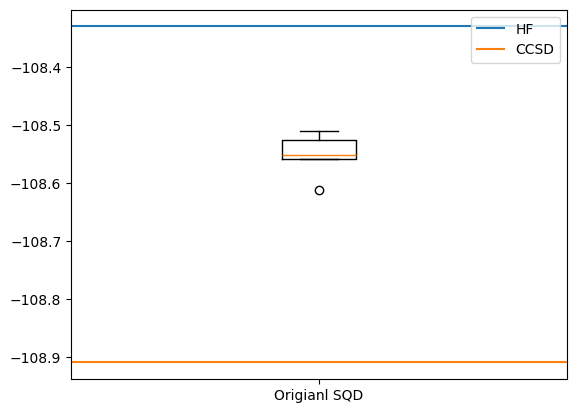

In [ ]:
print(f"Best energy = {best_result.energy + nuclear_repulsion_energy}")

plt.axhline(scf.e_tot, color="C0", label="HF")
plt.axhline(ccsd.e_tot, color="C1", label="CCSD")
plt.boxplot(
    [x.energy + nuclear_repulsion_energy for results in result_history for x in results],
    tick_labels=['Origianl SQD'],
)
plt.legend(loc='upper right')
plt.show()

# Will submit the best subspace basis
best_subspace = (best_result.sci_state.ci_strs_a, best_result.sci_state.ci_strs_b)

You may see that the original SQD method finds a better energy estimate than the HF state — this is already a non-trivial result, as it shows the quantum samples are steering the diagonalization into a physically meaningful region of Hilbert space.
However, the result is not yet as good as the classical CCSD benchmark.

The gap between SQD and CCSD reveals a limitation of pure sampling: hardware noise and finite shot counts mean the sampler misses some chemically important electron configurations — particularly the *low-energy*, *near-HF* configurations that contribute strongly to the ground state but may not be the *most frequently measured* bitstrings.

**Exercise 4 directly addresses this gap** by augmenting the sampled subspace with a hand-picked set of chemically motivated configurations.

## Exercise 4: Freeze subspace configurations

### Classical subspace diagonalization

Before combining classical and quantum subspaces, let's see what happens if we diagonalize in a *purely classical, physically motivated* subspace — no quantum samples at all.

The key insight is that the **lowest-energy electron configurations** are those closest to Hartree–Fock: the `num_elec` electrons sit in the lowest-energy orbitals, with only small rearrangements ("excitations") away from the HF reference.
We can enumerate these systematically using `itertools.combinations`:

In [ ]:
from itertools import combinations

print(list(combinations(range(5), 3)))

[(0, 1, 2), (0, 1, 3), (0, 1, 4), (0, 2, 3), (0, 2, 4), (0, 3, 4), (1, 2, 3), (1, 2, 4), (1, 3, 4), (2, 3, 4)]


<a id="exercise_4"></a>
<div class="alert alert-block alert-success">

<b>Exercise 4: Build an HF-like frozen subspace</b>

**Your Goal:** Construct `hf_like_bitstrings` — up to 300 Slater determinants built from the *lowest-orbital* electron configurations — and convert them to `hf_like_ci_strings` suitable for the eigensolver.

**Background:** Returning to our concert-hall analogy: instead of hoping the quantum sampler stumbles upon the most important seating arrangements, we manually enumerate the front-row configurations and hand them directly to the eigensolver.
The "front rows" here are the orbital combinations where electrons prefer to sit — the lowest-energy orbitals first, then progressively more excited arrangements.

**Hint:**
- Consider starting from a fully occupied bitstring.
- Apply `bitstring_matrix_to_integers` to convert to CI string format.
- Don't forget that you should provide both of α and β strings to run diagonalization!

</div>

In [ ]:
# ---- TODO : Task 4 ----

from itertools import combinations
import numpy as np

max_reference_determinants = 300

hf_like_bitstrings = []

# Start from a fully occupied bitstring.
# Unoccupy 26 - 5 = 21 orbitals, leaving exactly 5 electrons.
#
# The first combination removes orbitals 0 through 20,
# leaving orbitals 21 through 25 occupied: the HF configuration.
for unoccupied_orbitals in combinations(
    range(num_orbitals),
    num_orbitals - num_elec_a,
):
    bitstring = np.ones(
        num_orbitals,
        dtype=bool,
    )

    bitstring[list(unoccupied_orbitals)] = False

    hf_like_bitstrings.append(bitstring)

    if len(hf_like_bitstrings) == max_reference_determinants:
        break

# Shape: (300, 26)
hf_like_bitstrings = np.asarray(
    hf_like_bitstrings,
    dtype=bool,
)

# Convert the 300 two-dimensional bitstrings into CI integers.
# Shape: (300,)
one_spin_ci_strings = bitstring_matrix_to_integers(
    hf_like_bitstrings
)

# N2 is treated here with identical alpha and beta reference strings.
# Shape: (2, 300)
hf_like_ci_strings = np.stack(
    [
        one_spin_ci_strings,  # alpha
        one_spin_ci_strings,  # beta
    ],
    axis=0,
)

# Optional aliases for notebook versions using ref_* names.
ref_bitstrings = hf_like_bitstrings
ref_ci_strings = hf_like_ci_strings

# ---- End of TODO : Task 4 ----

In [ ]:
print("HF-like bitstrings shape:", hf_like_bitstrings.shape)
print("HF-like CI strings shape:", hf_like_ci_strings.shape)

print("\nFirst HF-like bitstring:")
print(hf_like_bitstrings[0])

print("\nFirst alpha CI string:", hf_like_ci_strings[0, 0])
print("First beta CI string: ", hf_like_ci_strings[1, 0])

HF-like bitstrings shape: (300, 26)
HF-like CI strings shape: (2, 300)

First HF-like bitstring:
[False False False False False False False False False False False False
 False False False False False False False False False  True  True  True
  True  True]

First alpha CI string: 31
First beta CI string:  31


In [ ]:
grade_lab4c_ex4(hf_like_ci_strings)

Grading your answer. Please wait...

Congratulations! 🎉 Your answer is correct.
You scored 1 on this exercise.


Now try diagonalizing the Hamiltonian in this purely classical, HF-like subspace:

In [ ]:
hf_result = sci_solver([hf_like_ci_strings], hcore, eri, num_orbitals, nelec)[0]
print(f"HF-like Subspace Diagonalized Energy: {hf_result.energy + nuclear_repulsion_energy}")
print(f"Subspace dimension: {np.prod(hf_result.sci_state.amplitudes.shape)}")

You may find that the HF-like subspace energy is **lower** than the original (pure quantum sampling) SQD result.
This confirms that the hand-picked low-energy configurations are genuinely important for the ground state, and that the quantum sampler alone might drop some important configurations due to the instable noisy environment.

### Combining quantum samples with a frozen classical subspace

The most powerful approach combines the two:
- Fix a small number of the HF-like configurations as a **guaranteed anchor** (`include = hf_like_ci_strings[:, :100]` — first 100 configurations).
- Let the quantum sampler supply the remaining `max_dim - 100` configurations per batch as usual.

This way, every diagonalization starts from a solid classical foundation and the quantum device explores the rest of the space.
How do you expect the result to compare to the pure-sampling and pure-HF cases?

In [ ]:
# List to capture intermediate results
pm_result_history = []

def callback(results: list[SCIResult]):
    pm_result_history.append(results)
    iteration = len(pm_result_history)
    print(f"Iteration {iteration}")
    for i, result in enumerate(results):
        print(f"\tSubsample {i}")
        print(f"\t\tEnergy: {result.energy + nuclear_repulsion_energy}")
        print(f"\t\tSubspace dimension: {np.prod(result.sci_state.amplitudes.shape)}")

# We are fixing 100 lowest orbital subspaces during the SQD loop.
# The remaining 200 samples are obtained from quantum samples as usual.
include = hf_like_ci_strings[:, :100]  # Fix 100 lowest orbital subspace

rng = np.random.default_rng(seed)
current_occupancies = initial_occupancy
best_result = None
sci_solver = solve_sci_batch

# Convert BitArray into bitstring and probability arrays
raw_bitstrings, raw_probs = bit_array_to_arrays(bit_array)

# Run configuration recovery loop
for _ in range(max_iterations):
    reshaped_bitstrings = reshape_bitstring(raw_bitstrings, num_orbitals)

    # If we do have average orbital occupancy information, use it to refine the
    # full set of noisy configurations
    bitstrings, probs = recover_configurations(
        reshaped_bitstrings, raw_probs, current_occupancies, num_orbitals, nelec, rand_seed=rng
    )

    # Subsample batches of bitstrings
    subsamples = np.array(subsample(
        bitstrings.reshape(-1, 2*num_orbitals),
        probs,
        samples_per_batch=samples_per_batch,
        num_batches=num_batches,
        rand_seed=rng,
    ))
    subsamples = subsamples.reshape(*subsamples.shape[:-1], 2, -1)

    ci_strs = np.array([bitstring_matrix_to_integers(samples[:, i]) for samples in subsamples for i in range(2)])
    ci_strs = ci_strs.reshape(-1, 2, ci_strs.shape[-1])

    # Convert bitstrings to CI strings and include requested and carryover strings
    subspace = build_subspace(ci_strs, include, max_dim=max_dim)

    # Run diagonalization
    results = sci_solver(subspace, hcore, eri, num_orbitals, nelec)

    # Call callback function
    callback(results)

    # Get best result from batch
    best_result_in_batch = min(results, key=lambda result: result.energy)

    # Check if the energy is the lowest seen so far
    if best_result is None or best_result_in_batch.energy < best_result.energy:
        best_result = copy.deepcopy(best_result_in_batch)

    # Save the current result and occupancies
    current_result = copy.deepcopy(best_result_in_batch)
    current_occupancies = current_result.orbital_occupancies

# best_result is not None because there must have been at least one iteration
best_result = cast(SCIResult, best_result)

In [ ]:
print(f"Best energy (frozen subspace) = {best_result.energy + nuclear_repulsion_energy}")

plt.axhline(scf.e_tot, color="C0", label="HF")
plt.axhline(ccsd.e_tot, color="C1", label="CCSD")
plt.axhline(hf_result.energy + nuclear_repulsion_energy, color="C2", label="HF-like subspace")
plt.boxplot(
    [[x.energy + nuclear_repulsion_energy for results in result_history for x in results],
     [x.energy + nuclear_repulsion_energy for results in pm_result_history for x in results]],
    tick_labels=["Origianl SQD", "Frozen Subspace SQD"],
)
plt.legend(loc='upper right')
plt.show()

Observe two improvements in the **Frozen Subspace SQD** box plot:

1. **Lower energy** — the best estimate is closer to the CCSD reference, because the 100 frozen HF-like configurations guarantee that the most important near-HF determinants are always in the subspace.
2. **Tighter spread** — the box plot is narrower, meaning the result is more *stable* across different batches. Anchoring the subspace reduces variance from unlucky sampling.

Note also: the HF-like subspace is *not* the best possible subspace — it is just a systematic and physically motivated choice. The quantum sampler can, in principle, discover configurations with even lower energy that no classical heuristic would have enumerated.
This is the promise of the scored exercise below.

### Scored Exercise: Find your best subspace!

<a id="exercise_bonus"></a>
<div class="alert alert-block alert-success">

**Your Goal:** Minimize `best_energy` — the ground-state energy estimate for N₂ — as far below the CCSD benchmark as you can push it.
The lower your energy, the higher your score.

**Metric:** `best_energy = best_result.energy + nuclear_repulsion_energy`. Lower is better.

**What you can change:** Anything! Some ideas:

- **Better ansatz:** add more LUCJ layers or further optimize the parameters to get better samples.
- **Better flip probability:** experiment with different functional forms for `prob_flip_0_to_1` (e.g. a steeper exponential, or a threshold function).
- **More iterations:** increase `max_iterations` or `num_batches` and let the occupancy prior converge further.
- **Classical post-processing:** try some classical algorithms to keep and carryover good bitstrings.

Submit your best result with the cell below.

</div>

In [ ]:
from qiskit_ibm_runtime import QiskitRuntimeService
from qiskit_addon_sqd.counts import bit_array_to_arrays

service = QiskitRuntimeService()

JOB_ID = "<YOUR_JOB_ID>"

job = service.job(JOB_ID)

print("Job ID:", job.job_id())
print("Status:", job.status())

primitive_result = job.result()
pub_result = primitive_result[0]
bit_array = pub_result.data.meas

raw_bitstrings, raw_probs = bit_array_to_arrays(
    bit_array
)

print("Samples recovered:", raw_bitstrings.shape)
print("Probability sum:", raw_probs.sum())

In [ ]:
seed = 142
print("Seed:", seed)

Seed: 142


In [ ]:
import numpy as np

# Restore variables cleared by the qBraid restart.
seed = 142

num_orbitals = 26
num_elec_a = 5
num_elec_b = 5

nelec = (
    num_elec_a,
    num_elec_b,
)

# Hartree-Fock occupancy:
# the final five orbitals are occupied for each spin sector.
initial_occupancy = np.zeros(
    (2, num_orbitals),
    dtype=float,
)

initial_occupancy[
    :,
    -num_elec_a:
] = 1.0

print("Seed:", seed)
print("Number of orbitals:", num_orbitals)
print("Electrons:", nelec)
print("Initial occupancy shape:", initial_occupancy.shape)
print("Electron counts:", initial_occupancy.sum(axis=1))

Seed: 142
Number of orbitals: 26
Electrons: (5, 5)
Initial occupancy shape: (2, 26)
Electron counts: [5. 5.]


In [ ]:
# ============================================================
# BLOCK 4: CORRECT LAB 4C HELPER FUNCTIONS
# ============================================================

from collections import defaultdict
import numpy as np


# ------------------------------------------------------------
# Reshape raw Qiskit bitstrings
# Raw order: beta, alpha
# Required order: alpha, beta
# ------------------------------------------------------------

def reshape_bitstring(
    bitstrings: np.ndarray,
    num_orbitals: int,
) -> np.ndarray:

    bitstrings = np.asarray(
        bitstrings,
        dtype=bool,
    )

    reshaped_bitstrings = bitstrings.reshape(
        bitstrings.shape[0],
        2,
        num_orbitals,
    )

    # Exchange beta and alpha blocks.
    reshaped_bitstrings = reshaped_bitstrings[
        :,
        [1, 0],
        :,
    ]

    return reshaped_bitstrings


# ------------------------------------------------------------
# Calculate electron counts
# ------------------------------------------------------------

def hamming_weight(
    bitstrings: np.ndarray,
) -> np.ndarray:

    return np.asarray(
        bitstrings
    ).sum(axis=-1)


# ------------------------------------------------------------
# Probability weights for electron recovery
# ------------------------------------------------------------

def weight_flip_0_to_1(
    occupancy: np.ndarray,
) -> np.ndarray:

    occupancy = np.asarray(
        occupancy,
        dtype=float,
    )

    return np.expm1(occupancy)


def weight_flip_1_to_0(
    occupancy: np.ndarray,
) -> np.ndarray:

    occupancy = np.asarray(
        occupancy,
        dtype=float,
    )

    return weight_flip_0_to_1(
        1.0 - occupancy
    )


# ------------------------------------------------------------
# Recover configurations with correct electron numbers
# ------------------------------------------------------------

def recover_configurations(
    bitstrings: np.ndarray,
    probs: np.ndarray,
    occupancy: np.ndarray,
    num_orbitals: int,
    num_elec: tuple[int, int],
    rand_seed: np.random.Generator,
) -> tuple[np.ndarray, np.ndarray]:

    bitstrings = np.asarray(
        bitstrings,
        dtype=bool,
    )

    probs = np.asarray(
        probs,
        dtype=float,
    )

    # SCI results may return occupancies as a tuple.
    if isinstance(occupancy, tuple):
        occupancy = np.stack(
            [
                np.asarray(spin_occ, dtype=float)
                for spin_occ in occupancy
            ],
            axis=0,
        )
    else:
        occupancy = np.asarray(
            occupancy,
            dtype=float,
        )

    corrected_dict = defaultdict(float)

    all_weights = hamming_weight(
        bitstrings
    )

    for bitstring, frequency, weight in zip(
        bitstrings,
        probs,
        all_weights,
    ):
        bs_corrected = bitstring.copy()

        # 0 = alpha, 1 = beta
        for spin_index in range(2):

            target_electrons = int(
                num_elec[spin_index]
            )

            current_electrons = int(
                weight[spin_index]
            )

            # ----------------------------------------
            # Too few electrons: change 0 to 1
            # ----------------------------------------

            if current_electrons < target_electrons:

                candidates = np.where(
                    bs_corrected[spin_index] == 0
                )[0]

                number_to_flip = (
                    target_electrons
                    - current_electrons
                )

                flip_probs = weight_flip_0_to_1(
                    occupancy[
                        spin_index,
                        candidates,
                    ]
                )

                if np.isclose(
                    flip_probs.sum(),
                    0.0,
                ):
                    flip_probs = np.ones(
                        len(candidates),
                        dtype=float,
                    )

                flip_probs = (
                    flip_probs
                    / flip_probs.sum()
                )

                chosen = rand_seed.choice(
                    candidates,
                    size=number_to_flip,
                    replace=False,
                    p=flip_probs,
                )

                bs_corrected[
                    spin_index,
                    chosen,
                ] = True

            # ----------------------------------------
            # Too many electrons: change 1 to 0
            # ----------------------------------------

            elif current_electrons > target_electrons:

                candidates = np.where(
                    bs_corrected[spin_index] == 1
                )[0]

                number_to_flip = (
                    current_electrons
                    - target_electrons
                )

                flip_probs = weight_flip_1_to_0(
                    occupancy[
                        spin_index,
                        candidates,
                    ]
                )

                if np.isclose(
                    flip_probs.sum(),
                    0.0,
                ):
                    flip_probs = np.ones(
                        len(candidates),
                        dtype=float,
                    )

                flip_probs = (
                    flip_probs
                    / flip_probs.sum()
                )

                chosen = rand_seed.choice(
                    candidates,
                    size=number_to_flip,
                    replace=False,
                    p=flip_probs,
                )

                bs_corrected[
                    spin_index,
                    chosen,
                ] = False

        # Combine identical corrected configurations.
        bitstring_key = "".join(
            "1" if bit else "0"
            for bit in bs_corrected.flatten()
        )

        corrected_dict[bitstring_key] += float(
            frequency
        )

    corrected_bitstrings = np.array(
        [
            [
                character == "1"
                for character in bitstring
            ]
            for bitstring in corrected_dict
        ],
        dtype=bool,
    ).reshape(
        -1,
        2,
        num_orbitals,
    )

    corrected_probs = np.array(
        list(corrected_dict.values()),
        dtype=float,
    )

    corrected_probs = np.abs(
        corrected_probs
    )

    corrected_probs /= corrected_probs.sum()

    return (
        corrected_bitstrings,
        corrected_probs,
    )


# ------------------------------------------------------------
# Build alpha/beta selected-CI subspaces
# ------------------------------------------------------------

def build_subspace(
    subsamples,
    include=None,
    max_dim=(None, None),
):

    if include is None:
        include = np.empty(
            (2, 0),
            dtype=np.int64,
        )

    include = np.asarray(
        include,
        dtype=np.int64,
    )

    subspaces = []

    for samples in subsamples:

        spin_subspaces = []

        for spin_index in range(2):

            ci_strings, counts = np.unique(
                samples[spin_index],
                return_counts=True,
            )

            # Highest-frequency strings first.
            ci_strings = ci_strings[
                np.argsort(counts)[::-1]
            ]

            # Reference strings receive priority.
            subspace = np.concatenate(
                [
                    include[spin_index],
                    ci_strings,
                ]
            )

            # Remove duplicates while preserving order.
            _, unique_indices = np.unique(
                subspace,
                return_index=True,
            )

            unique_indices.sort()

            subspace = subspace[
                unique_indices
            ]

            limit = max_dim[spin_index]

            if limit is not None:
                subspace = subspace[
                    :int(limit)
                ]

            # PySCF expects sorted CI strings.
            subspace = np.sort(
                subspace
            )

            spin_subspaces.append(
                subspace
            )

        subspaces.append(
            spin_subspaces
        )

    return subspaces


# ------------------------------------------------------------
# Verify the functions
# ------------------------------------------------------------

reshaped_bitstrings = reshape_bitstring(
    raw_bitstrings,
    num_orbitals,
)

print(
    "Reshaped bitstrings:",
    reshaped_bitstrings.shape,
)

print(
    "First electron counts:",
    hamming_weight(
        reshaped_bitstrings
    )[0],
)

test_rng = np.random.default_rng(
    seed
)

test_bitstrings, test_probs = (
    recover_configurations(
        reshaped_bitstrings,
        raw_probs,
        initial_occupancy,
        num_orbitals,
        nelec,
        test_rng,
    )
)

test_weights = hamming_weight(
    test_bitstrings
)

print(
    "Recovered configurations:",
    test_bitstrings.shape,
)

print(
    "Probability sum:",
    test_probs.sum(),
)

print(
    "All electron counts valid:",
    np.all(
        test_weights
        == np.asarray(nelec)
    ),
)

Reshaped bitstrings: (2000, 2, 26)
First electron counts: [10  7]
Recovered configurations: (1999, 2, 26)
Probability sum: 0.9999999999999993
All electron counts valid: True


In [ ]:
test_rng = np.random.default_rng(seed)

test_bitstrings, test_probs = recover_configurations(
    reshaped_bitstrings,
    raw_probs,
    initial_occupancy,
    num_orbitals,
    nelec,
    test_rng,
)

test_weights = hamming_weight(
    test_bitstrings
)

print(
    "Recovered configurations:",
    test_bitstrings.shape,
)

print(
    "Probability sum:",
    test_probs.sum(),
)

print(
    "All electron counts valid:",
    np.all(
        test_weights
        == np.asarray(nelec)
    ),
)

Recovered configurations: (1999, 2, 26)
Probability sum: 0.9999999999999993
All electron counts valid: True


In [ ]:
# ============================================================
# BLOCK 5: RECREATE HF-LIKE REFERENCE CONFIGURATIONS
# ============================================================

import numpy as np

from itertools import combinations

from qiskit_addon_sqd.counts import (
    bitstring_matrix_to_integers,
)


max_reference_determinants = 300

hf_like_bitstrings = []


# ------------------------------------------------------------
# Generate the first 300 lowest-orbital configurations
# ------------------------------------------------------------

for unoccupied_orbitals in combinations(
    range(num_orbitals),
    num_orbitals - num_elec_a,
):

    bitstring = np.ones(
        num_orbitals,
        dtype=bool,
    )

    bitstring[
        list(unoccupied_orbitals)
    ] = False

    hf_like_bitstrings.append(
        bitstring
    )

    if (
        len(hf_like_bitstrings)
        == max_reference_determinants
    ):
        break


hf_like_bitstrings = np.asarray(
    hf_like_bitstrings,
    dtype=bool,
)


# ------------------------------------------------------------
# Convert Boolean orbital configurations into CI integers
# ------------------------------------------------------------

one_spin_ci_strings = (
    bitstring_matrix_to_integers(
        hf_like_bitstrings
    )
)


# Use identical reference lists for alpha and beta.
hf_like_ci_strings = np.stack(
    [
        one_spin_ci_strings,
        one_spin_ci_strings,
    ],
    axis=0,
).astype(np.int64)


# Names used by the bonus code.
ref_bitstrings = hf_like_bitstrings
ref_ci_strings = hf_like_ci_strings


# ------------------------------------------------------------
# Verify
# ------------------------------------------------------------

print(
    "HF-like bitstrings shape:",
    hf_like_bitstrings.shape,
)

print(
    "HF-like CI strings shape:",
    hf_like_ci_strings.shape,
)

print(
    "First HF-like bitstring:",
    hf_like_bitstrings[0],
)

print(
    "First alpha CI string:",
    hf_like_ci_strings[0, 0],
)

print(
    "First beta CI string:",
    hf_like_ci_strings[1, 0],
)

assert hf_like_bitstrings.shape == (
    300,
    num_orbitals,
)

assert hf_like_ci_strings.shape == (
    2,
    300,
)

print(
    "\nHF reference subspace is ready."
)

HF-like bitstrings shape: (300, 26)
HF-like CI strings shape: (2, 300)
First HF-like bitstring: [False False False False False False False False False False False False
 False False False False False False False False False  True  True  True
  True  True]
First alpha CI string: 31
First beta CI string: 31

HF reference subspace is ready.


In [ ]:
required_names = [
    "hcore",
    "eri",
    "nuclear_repulsion_energy",
    "num_orbitals",
    "num_elec_a",
    "num_elec_b",
    "nelec",
    "initial_occupancy",
    "seed",
    "bit_array",
    "raw_bitstrings",
    "raw_probs",
    "reshape_bitstring",
    "hamming_weight",
    "recover_configurations",
    "build_subspace",
    "ref_ci_strings",
]

missing_names = [
    name
    for name in required_names
    if name not in globals()
]

if missing_names:
    print("Missing variables:")
    for name in missing_names:
        print(" -", name)
else:
    print("Everything required for the bonus is ready.")

Everything required for the bonus is ready.


In [ ]:
# ============================================================
# LAB 4C BONUS — IMPROVED SELECTED-CI SUBSPACE SEARCH
# ============================================================

import copy
import gc
import numpy as np

from functools import partial
from typing import cast

from qiskit_addon_sqd.fermion import (
    SCIResult,
    solve_sci_batch,
)

from qiskit_addon_sqd.subsampling import (
    subsample,
)

from qiskit_addon_sqd.counts import (
    bit_array_to_arrays,
    bitstring_matrix_to_integers,
)


# ============================================================
# 1. Confirm that all required variables exist
# ============================================================

required_names = [
    "hcore",
    "eri",
    "nuclear_repulsion_energy",
    "num_orbitals",
    "num_elec_a",
    "num_elec_b",
    "nelec",
    "initial_occupancy",
    "seed",
    "bit_array",
    "reshape_bitstring",
    "hamming_weight",
    "recover_configurations",
    "build_subspace",
    "ref_ci_strings",
]

missing_names = [
    name
    for name in required_names
    if name not in globals()
]

if missing_names:
    raise NameError(
        "The following variables/functions are missing:\n"
        + "\n".join(
            f" - {name}"
            for name in missing_names
        )
    )

print("All required variables are available.")


# ============================================================
# 2. Bonus calculation settings
# ============================================================

# Two independent searches improve exploration.
number_of_searches = 2

# Number of occupancy-refinement iterations per search.
iterations_per_search = 4

# Independent subspaces solved during each iteration.
num_batches_bonus = 5

# Quantum configurations sampled for each subspace.
samples_per_batch_bonus = 500

# Maximum number of alpha and beta CI strings.
# 250 × 250 = 62,500 possible determinant pairs.
max_dim_bonus = (
    250,
    250,
)

# Chemically motivated reference configurations.
reference_count = 100

# Best alpha and beta strings carried into the next iteration.
elite_count = 40

# Use the spin-singlet eigensolver.
sci_solver_bonus = partial(
    solve_sci_batch,
    spin_sq=0.0,
    max_cycle=200,
)


# ============================================================
# 3. Recover the existing quantum samples
# ============================================================

raw_bitstrings, raw_probs = bit_array_to_arrays(
    bit_array
)

raw_bitstrings = np.asarray(
    raw_bitstrings,
    dtype=bool,
)

raw_probs = np.asarray(
    raw_probs,
    dtype=float,
)

raw_probs = np.abs(raw_probs)
raw_probs /= raw_probs.sum()

reshaped_raw_bitstrings = reshape_bitstring(
    raw_bitstrings,
    num_orbitals,
)

print(
    "Raw samples:",
    raw_bitstrings.shape,
)

print(
    "Reshaped samples:",
    reshaped_raw_bitstrings.shape,
)

print(
    "Raw probability sum:",
    raw_probs.sum(),
)


# ============================================================
# 4. Prepare reference CI strings
# ============================================================

reference_ci_strings = np.asarray(
    ref_ci_strings[
        :,
        :reference_count,
    ],
    dtype=np.int64,
)

print(
    "Pinned reference strings:",
    reference_ci_strings.shape,
)


# ============================================================
# 5. Storage for the best result
# ============================================================

bonus_best_result = None
bonus_best_energy = np.inf

bonus_energy_history = []
bonus_result_history = []


# ============================================================
# 6. Run independent bonus searches
# ============================================================

for search_index in range(
    number_of_searches
):

    print("\n")
    print("=" * 65)
    print(
        f"STARTING BONUS SEARCH "
        f"{search_index + 1}/"
        f"{number_of_searches}"
    )
    print("=" * 65)

    rng_bonus = np.random.default_rng(
        seed
        + 1000
        + search_index
    )

    current_occupancies = np.asarray(
        initial_occupancy,
        dtype=float,
    ).copy()

    # Elite strings are initially empty.
    elite_alpha = np.empty(
        0,
        dtype=np.int64,
    )

    elite_beta = np.empty(
        0,
        dtype=np.int64,
    )


    for iteration in range(
        iterations_per_search
    ):

        print("\n" + "-" * 65)

        print(
            f"Search {search_index + 1}, "
            f"iteration {iteration + 1}/"
            f"{iterations_per_search}"
        )

        print("-" * 65)


        # ====================================================
        # A. Correct noisy quantum configurations
        # ====================================================

        corrected_bitstrings, corrected_probs = (
            recover_configurations(
                reshaped_raw_bitstrings,
                raw_probs,
                current_occupancies,
                num_orbitals,
                nelec,
                rand_seed=rng_bonus,
            )
        )

        corrected_bitstrings = np.asarray(
            corrected_bitstrings,
            dtype=bool,
        )

        corrected_probs = np.asarray(
            corrected_probs,
            dtype=float,
        )

        corrected_probs = np.abs(
            corrected_probs
        )

        corrected_probs /= (
            corrected_probs.sum()
        )

        corrected_weights = hamming_weight(
            corrected_bitstrings
        )

        valid_electron_counts = np.all(
            corrected_weights
            == np.asarray(nelec)
        )

        print(
            "Corrected configurations:",
            corrected_bitstrings.shape[0],
        )

        print(
            "Valid electron counts:",
            valid_electron_counts,
        )

        if not valid_electron_counts:
            raise ValueError(
                "Configuration recovery produced "
                "invalid electron counts."
            )


        # ====================================================
        # B. Generate independent subsamples
        # ====================================================

        flattened_bitstrings = (
            corrected_bitstrings.reshape(
                corrected_bitstrings.shape[0],
                2 * num_orbitals,
            )
        )

        sampled_batches = np.asarray(
            subsample(
                flattened_bitstrings,
                corrected_probs,
                samples_per_batch=(
                    samples_per_batch_bonus
                ),
                num_batches=(
                    num_batches_bonus
                ),
                rand_seed=rng_bonus,
            )
        )

        sampled_batches = (
            sampled_batches.reshape(
                sampled_batches.shape[0],
                sampled_batches.shape[1],
                2,
                num_orbitals,
            )
        )

        print(
            "Sampled batches:",
            sampled_batches.shape,
        )


        # ====================================================
        # C. Convert Boolean strings into CI integers
        # ====================================================

        ci_batches = []

        for sampled_batch in sampled_batches:

            alpha_strings = (
                bitstring_matrix_to_integers(
                    sampled_batch[
                        :,
                        0,
                        :,
                    ]
                )
            )

            beta_strings = (
                bitstring_matrix_to_integers(
                    sampled_batch[
                        :,
                        1,
                        :,
                    ]
                )
            )

            ci_batch = np.stack(
                [
                    alpha_strings,
                    beta_strings,
                ],
                axis=0,
            ).astype(np.int64)

            ci_batches.append(
                ci_batch
            )

        ci_batches = np.asarray(
            ci_batches,
            dtype=np.int64,
        )

        print(
            "CI batch shape:",
            ci_batches.shape,
        )


        # ====================================================
        # D. Combine references with elite strings
        # ====================================================

        # Keep equal alpha/beta elite-list lengths so that the
        # include array remains rectangular.
        number_of_elites = min(
            elite_count,
            len(elite_alpha),
            len(elite_beta),
        )

        if number_of_elites > 0:

            include_alpha = np.concatenate(
                [
                    reference_ci_strings[0],
                    elite_alpha[
                        :number_of_elites
                    ],
                ]
            )

            include_beta = np.concatenate(
                [
                    reference_ci_strings[1],
                    elite_beta[
                        :number_of_elites
                    ],
                ]
            )

        else:
            include_alpha = (
                reference_ci_strings[0].copy()
            )

            include_beta = (
                reference_ci_strings[1].copy()
            )

        include_ci_strings = np.stack(
            [
                include_alpha,
                include_beta,
            ],
            axis=0,
        ).astype(np.int64)

        print(
            "Pinned strings per spin:",
            include_ci_strings.shape[1],
        )


        # ====================================================
        # E. Build the selected-CI subspaces
        # ====================================================

        subspaces = build_subspace(
            ci_batches,
            include=include_ci_strings,
            max_dim=max_dim_bonus,
        )

        print(
            "Number of subspaces:",
            len(subspaces),
        )

        for batch_index, subspace in enumerate(
            subspaces
        ):
            print(
                f"  Batch {batch_index + 1}: "
                f"alpha={len(subspace[0])}, "
                f"beta={len(subspace[1])}"
            )


        # ====================================================
        # F. Diagonalise all subspaces
        # ====================================================

        results = sci_solver_bonus(
            subspaces,
            hcore,
            eri,
            num_orbitals,
            nelec,
        )

        bonus_result_history.append(
            results
        )

        total_energies = np.asarray(
            [
                result.energy
                + nuclear_repulsion_energy
                for result in results
            ],
            dtype=float,
        )

        best_batch_index = int(
            np.argmin(total_energies)
        )

        best_this_iteration = results[
            best_batch_index
        ]

        energy_this_iteration = float(
            total_energies[
                best_batch_index
            ]
        )

        bonus_energy_history.append(
            energy_this_iteration
        )

        print("\nBatch energies:")

        for batch_index, energy in enumerate(
            total_energies
        ):
            print(
                f"  Batch {batch_index + 1}: "
                f"{energy:.12f} Hartree"
            )

        print(
            "\nBest energy this iteration:",
            f"{energy_this_iteration:.12f}",
        )


        # ====================================================
        # G. Store the global best result
        # ====================================================

        if (
            bonus_best_result is None
            or energy_this_iteration
            < bonus_best_energy
        ):

            bonus_best_result = copy.deepcopy(
                best_this_iteration
            )

            bonus_best_energy = (
                energy_this_iteration
            )

            print(
                "*** NEW GLOBAL BEST ENERGY ***"
            )

            # Save enough information to recover after another
            # qBraid restart.
            np.savez(
                "lab4c_bonus_best.npz",
                best_energy=np.float64(
                    bonus_best_energy
                ),
                ci_strs_a=np.asarray(
                    bonus_best_result
                    .sci_state
                    .ci_strs_a,
                    dtype=np.int64,
                ),
                ci_strs_b=np.asarray(
                    bonus_best_result
                    .sci_state
                    .ci_strs_b,
                    dtype=np.int64,
                ),
            )

            print(
                "Checkpoint saved as "
                "lab4c_bonus_best.npz"
            )


        # ====================================================
        # H. Update orbital occupancies
        # ====================================================

        occupancy_data = (
            best_this_iteration
            .orbital_occupancies
        )

        if isinstance(
            occupancy_data,
            tuple,
        ):
            current_occupancies = np.stack(
                [
                    np.asarray(
                        spin_occupancy,
                        dtype=float,
                    )
                    for spin_occupancy
                    in occupancy_data
                ],
                axis=0,
            )
        else:
            current_occupancies = np.asarray(
                occupancy_data,
                dtype=float,
            )

        if current_occupancies.shape != (
            2,
            num_orbitals,
        ):
            raise ValueError(
                "Unexpected orbital-occupancy shape: "
                f"{current_occupancies.shape}"
            )


        # ====================================================
        # I. Select important strings for the next iteration
        # ====================================================

        amplitudes = np.abs(
            np.asarray(
                best_this_iteration
                .sci_state
                .amplitudes
            )
        )

        alpha_importance = amplitudes.sum(
            axis=1
        )

        beta_importance = amplitudes.sum(
            axis=0
        )

        available_alpha = np.asarray(
            best_this_iteration
            .sci_state
            .ci_strs_a,
            dtype=np.int64,
        )

        available_beta = np.asarray(
            best_this_iteration
            .sci_state
            .ci_strs_b,
            dtype=np.int64,
        )

        number_of_elites = min(
            elite_count,
            len(available_alpha),
            len(available_beta),
        )

        alpha_order = np.argsort(
            alpha_importance
        )[::-1]

        beta_order = np.argsort(
            beta_importance
        )[::-1]

        elite_alpha = available_alpha[
            alpha_order[
                :number_of_elites
            ]
        ]

        elite_beta = available_beta[
            beta_order[
                :number_of_elites
            ]
        ]

        print(
            "Elite alpha strings retained:",
            len(elite_alpha),
        )

        print(
            "Elite beta strings retained:",
            len(elite_beta),
        )


        # Release large temporary objects.
        del corrected_bitstrings
        del corrected_probs
        del corrected_weights
        del flattened_bitstrings
        del sampled_batches
        del ci_batches
        del subspaces
        del results

        gc.collect()


# ============================================================
# 7. Prepare the final bonus answer
# ============================================================

bonus_best_result = cast(
    SCIResult,
    bonus_best_result,
)

best_energy = np.float64(
    bonus_best_result.energy
    + nuclear_repulsion_energy
)

best_subspace = (
    np.asarray(
        bonus_best_result
        .sci_state
        .ci_strs_a,
        dtype=np.int64,
    ),

    np.asarray(
        bonus_best_result
        .sci_state
        .ci_strs_b,
        dtype=np.int64,
    ),
)


# ============================================================
# 8. Display the final result
# ============================================================

print("\n")
print("=" * 65)
print("FINAL LAB 4C BONUS RESULT")
print("=" * 65)

print(
    "Best energy:",
    f"{best_energy:.12f} Hartree",
)

print(
    "Alpha CI strings:",
    len(best_subspace[0]),
)

print(
    "Beta CI strings:",
    len(best_subspace[1]),
)

print(
    "Number of energies tested:",
    len(bonus_energy_history),
)

print(
    "Checkpoint file:",
    "lab4c_bonus_best.npz",
)

All required variables are available.
Raw samples: (2000, 52)
Reshaped samples: (2000, 2, 26)
Raw probability sum: 0.9999999999999993
Pinned reference strings: (2, 100)


STARTING BONUS SEARCH 1/2

-----------------------------------------------------------------
Search 1, iteration 1/4
-----------------------------------------------------------------
Corrected configurations: 1999
Valid electron counts: True
Sampled batches: (5, 500, 2, 26)
CI batch shape: (5, 2, 500)
Pinned strings per spin: 100
Number of subspaces: 5
  Batch 1: alpha=250, beta=250
  Batch 2: alpha=250, beta=250
  Batch 3: alpha=250, beta=250
  Batch 4: alpha=250, beta=250
  Batch 5: alpha=250, beta=250

Batch energies:
  Batch 1: -108.789534219353 Hartree
  Batch 2: -108.780869096655 Hartree
  Batch 3: -108.777196297154 Hartree
  Batch 4: -108.783107071873 Hartree
  Batch 5: -108.782252131821 Hartree

Best energy this iteration: -108.789534219353
*** NEW GLOBAL BEST ENERGY ***
Checkpoint saved as lab4c_bonus_best.np

In [ ]:
# ============================================================
# CONTINUE THE INTERRUPTED BONUS — ONE BATCH AT A TIME
# ============================================================

import os
import gc
import numpy as np

from qiskit_addon_sqd.fermion import solve_sci_batch


CHECKPOINT_FILE = "lab4c_bonus_best.npz"


def load_bonus_checkpoint():

    if not os.path.exists(CHECKPOINT_FILE):
        return (
            np.inf,
            None,
        )

    with np.load(CHECKPOINT_FILE) as data:

        saved_energy = float(
            data["best_energy"]
        )

        saved_subspace = (
            np.asarray(
                data["ci_strs_a"],
                dtype=np.int64,
            ),
            np.asarray(
                data["ci_strs_b"],
                dtype=np.int64,
            ),
        )

    return (
        saved_energy,
        saved_subspace,
    )


def save_bonus_checkpoint(
    energy,
    result,
):

    np.savez(
        CHECKPOINT_FILE,

        best_energy=np.float64(
            energy
        ),

        ci_strs_a=np.asarray(
            result.sci_state.ci_strs_a,
            dtype=np.int64,
        ),

        ci_strs_b=np.asarray(
            result.sci_state.ci_strs_b,
            dtype=np.int64,
        ),
    )


def run_bonus_batch(
    batch_index: int,
):

    if "subspaces" not in globals():
        raise NameError(
            "The variable 'subspaces' is missing. "
            "The kernel may have restarted."
        )

    if not 0 <= batch_index < len(subspaces):
        raise IndexError(
            f"batch_index must be between "
            f"0 and {len(subspaces) - 1}."
        )

    saved_energy, _ = (
        load_bonus_checkpoint()
    )

    trial_subspace = (
        np.asarray(
            subspaces[batch_index][0],
            dtype=np.int64,
        ),
        np.asarray(
            subspaces[batch_index][1],
            dtype=np.int64,
        ),
    )

    print("=" * 60)

    print(
        f"Running batch {batch_index + 1}/"
        f"{len(subspaces)}"
    )

    print(
        "Alpha strings:",
        len(trial_subspace[0]),
    )

    print(
        "Beta strings:",
        len(trial_subspace[1]),
    )

    print(
        "Current saved energy:",
        saved_energy,
    )

    print(
        "Beginning diagonalisation..."
    )

    # Only ONE subspace is submitted to the solver.
    #
    # spin_sq=None avoids the additional spin-penalty calculation.
    # max_cycle=100 is lower than the previous value of 200.
    result = solve_sci_batch(
        [trial_subspace],
        hcore,
        eri,
        num_orbitals,
        nelec,
        spin_sq=None,
        max_cycle=100,
        tol=1e-7,
    )[0]

    total_energy = float(
        result.energy
        + nuclear_repulsion_energy
    )

    print(
        "\nCompleted energy:",
        f"{total_energy:.12f}",
    )

    if total_energy < saved_energy:

        save_bonus_checkpoint(
            total_energy,
            result,
        )

        print(
            "*** New lower energy saved ***"
        )

    else:

        print(
            "No improvement over the "
            "existing checkpoint."
        )

    del result
    gc.collect()

    final_energy, final_subspace = (
        load_bonus_checkpoint()
    )

    print(
        "Best saved energy:",
        f"{final_energy:.12f}",
    )

    print("=" * 60)

    return final_energy

In [ ]:
# ============================================================
# RESTORE LAB 4C MOLECULE AND HAMILTONIAN
# ============================================================

import copy
import os
import gc
import numpy as np
import pyscf

from collections import defaultdict
from itertools import combinations
from functools import partial
from typing import cast

from qiskit_addon_sqd.fermion import (
    SCIResult,
    solve_sci_batch,
)

from qiskit_addon_sqd.subsampling import subsample

from qiskit_addon_sqd.counts import (
    bit_array_to_arrays,
    bitstring_matrix_to_integers,
)


# Build N2 molecule
mol = gto.Mole()

mol.build(
    atom=[
        ["N", (0, 0, 0)],
        ["N", (2.0, 0, 0)],
    ],
    basis="cc-pvdz",
)

# Define active space
n_frozen = 2
active_space = range(
    n_frozen,
    mol.nao_nr(),
)

# Hartree-Fock calculation
scf_result = scf.RHF(mol).run()

num_orbitals = len(active_space)

n_electrons = int(
    sum(scf_result.mo_occ[active_space])
)

num_elec_a = (
    n_electrons + mol.spin
) // 2

num_elec_b = (
    n_electrons - mol.spin
) // 2

nelec = (
    num_elec_a,
    num_elec_b,
)

# Active-space calculation
cas = mcscf.CASCI(
    scf_result,
    num_orbitals,
    nelec,
)

mo = cas.sort_mo(
    active_space,
    base=0,
)

hcore, nuclear_repulsion_energy = (
    cas.get_h1cas(mo)
)

eri = ao2mo.restore(
    1,
    cas.get_h2cas(mo),
    num_orbitals,
)

# Restore required SQD variables
seed = 142

initial_occupancy = np.zeros(
    (2, num_orbitals),
    dtype=float,
)

initial_occupancy[
    :,
    -num_elec_a:
] = 1.0

print("Number of orbitals:", num_orbitals)
print("Electrons:", nelec)
print("hcore shape:", hcore.shape)
print("ERI shape:", eri.shape)
print(
    "Occupancy counts:",
    initial_occupancy.sum(axis=1),
)


print("Number of orbitals:", num_orbitals)
print("Electrons:", nelec)
print("Hamiltonian shape:", hcore.shape)
print("ERI shape:", eri.shape)
print("Occupancy shape:", initial_occupancy.shape)
print("Occupancy counts:", initial_occupancy.sum(axis=1))

converged SCF energy = -108.33058275366
Number of orbitals: 26
Electrons: (5, 5)
hcore shape: (26, 26)
ERI shape: (26, 26, 26, 26)
Occupancy counts: [5. 5.]
Number of orbitals: 26
Electrons: (5, 5)
Hamiltonian shape: (26, 26)
ERI shape: (26, 26, 26, 26)
Occupancy shape: (2, 26)
Occupancy counts: [5. 5.]


In [ ]:
from pyscf import gto, scf, mcscf, ao2mo

print("PySCF submodules imported successfully.")

PySCF submodules imported successfully.


In [ ]:
# ============================================================
# RECOVER THE COMPLETED IBM QUANTUM JOB
# ============================================================

from qiskit_ibm_runtime import QiskitRuntimeService
from qiskit_addon_sqd.counts import bit_array_to_arrays

service = QiskitRuntimeService()

job_id = "<YOUR_JOB_ID>"

job = service.job(job_id)

print("Job status:", job.status())

primitive_result = job.result()

pub_result = primitive_result[0]

bit_array = pub_result.data.meas

raw_bitstrings, raw_probs = bit_array_to_arrays(
    bit_array
)

print("Raw bitstrings shape:", raw_bitstrings.shape)
print("Raw probabilities shape:", raw_probs.shape)
print("Probability sum:", raw_probs.sum())

In [ ]:
# ============================================================
# BLOCK 4: CORRECT LAB 4C HELPER FUNCTIONS
# ============================================================

from collections import defaultdict
import numpy as np


def reshape_bitstring(
    bitstrings: np.ndarray,
    num_orbitals: int,
) -> np.ndarray:

    bitstrings = np.asarray(
        bitstrings,
        dtype=bool,
    )

    reshaped_bitstrings = bitstrings.reshape(
        bitstrings.shape[0],
        2,
        num_orbitals,
    )

    # Raw Qiskit ordering is beta, alpha.
    # Swap it into alpha, beta ordering.
    reshaped_bitstrings = reshaped_bitstrings[
        :,
        [1, 0],
        :,
    ]

    return reshaped_bitstrings


def hamming_weight(
    bitstrings: np.ndarray,
) -> np.ndarray:

    return np.asarray(
        bitstrings
    ).sum(axis=-1)


def weight_flip_0_to_1(
    occupancy: np.ndarray,
) -> np.ndarray:

    occupancy = np.asarray(
        occupancy,
        dtype=float,
    )

    return np.expm1(occupancy)


def weight_flip_1_to_0(
    occupancy: np.ndarray,
) -> np.ndarray:

    occupancy = np.asarray(
        occupancy,
        dtype=float,
    )

    return weight_flip_0_to_1(
        1.0 - occupancy
    )


def recover_configurations(
    bitstrings: np.ndarray,
    probs: np.ndarray,
    occupancy: np.ndarray,
    num_orbitals: int,
    num_elec: tuple[int, int],
    rand_seed: np.random.Generator,
) -> tuple[np.ndarray, np.ndarray]:

    bitstrings = np.asarray(
        bitstrings,
        dtype=bool,
    )

    probs = np.asarray(
        probs,
        dtype=float,
    )

    if isinstance(occupancy, tuple):

        occupancy = np.stack(
            [
                np.asarray(
                    spin_occ,
                    dtype=float,
                )
                for spin_occ in occupancy
            ],
            axis=0,
        )

    else:

        occupancy = np.asarray(
            occupancy,
            dtype=float,
        )

    corrected_dict = defaultdict(float)

    all_weights = hamming_weight(
        bitstrings
    )

    for bitstring, frequency, weight in zip(
        bitstrings,
        probs,
        all_weights,
    ):

        bs_corrected = bitstring.copy()

        for spin_index in range(2):

            target_electrons = int(
                num_elec[spin_index]
            )

            current_electrons = int(
                weight[spin_index]
            )

            # Add electrons when there are too few.
            if current_electrons < target_electrons:

                candidates = np.where(
                    bs_corrected[spin_index] == 0
                )[0]

                number_to_flip = (
                    target_electrons
                    - current_electrons
                )

                flip_probs = weight_flip_0_to_1(
                    occupancy[
                        spin_index,
                        candidates,
                    ]
                )

                if np.isclose(
                    flip_probs.sum(),
                    0.0,
                ):
                    flip_probs = np.ones(
                        len(candidates),
                        dtype=float,
                    )

                flip_probs = (
                    flip_probs
                    / flip_probs.sum()
                )

                chosen = rand_seed.choice(
                    candidates,
                    size=number_to_flip,
                    replace=False,
                    p=flip_probs,
                )

                bs_corrected[
                    spin_index,
                    chosen,
                ] = True

            # Remove electrons when there are too many.
            elif current_electrons > target_electrons:

                candidates = np.where(
                    bs_corrected[spin_index] == 1
                )[0]

                number_to_flip = (
                    current_electrons
                    - target_electrons
                )

                flip_probs = weight_flip_1_to_0(
                    occupancy[
                        spin_index,
                        candidates,
                    ]
                )

                if np.isclose(
                    flip_probs.sum(),
                    0.0,
                ):
                    flip_probs = np.ones(
                        len(candidates),
                        dtype=float,
                    )

                flip_probs = (
                    flip_probs
                    / flip_probs.sum()
                )

                chosen = rand_seed.choice(
                    candidates,
                    size=number_to_flip,
                    replace=False,
                    p=flip_probs,
                )

                bs_corrected[
                    spin_index,
                    chosen,
                ] = False

        bitstring_key = "".join(
            "1" if bit else "0"
            for bit in bs_corrected.flatten()
        )

        corrected_dict[
            bitstring_key
        ] += float(frequency)

    corrected_bitstrings = np.array(
        [
            [
                character == "1"
                for character in bitstring
            ]
            for bitstring in corrected_dict
        ],
        dtype=bool,
    ).reshape(
        -1,
        2,
        num_orbitals,
    )

    corrected_probs = np.array(
        list(corrected_dict.values()),
        dtype=float,
    )

    corrected_probs = np.abs(
        corrected_probs
    )

    corrected_probs /= corrected_probs.sum()

    return (
        corrected_bitstrings,
        corrected_probs,
    )


def build_subspace(
    subsamples,
    include=None,
    max_dim=(None, None),
):

    if include is None:

        include = np.empty(
            (2, 0),
            dtype=np.int64,
        )

    include = np.asarray(
        include,
        dtype=np.int64,
    )

    subspaces = []

    for samples in subsamples:

        spin_subspaces = []

        for spin_index in range(2):

            ci_strings, counts = np.unique(
                samples[spin_index],
                return_counts=True,
            )

            ci_strings = ci_strings[
                np.argsort(counts)[::-1]
            ]

            subspace = np.concatenate(
                [
                    include[spin_index],
                    ci_strings,
                ]
            )

            _, unique_indices = np.unique(
                subspace,
                return_index=True,
            )

            unique_indices.sort()

            subspace = subspace[
                unique_indices
            ]

            limit = max_dim[spin_index]

            if limit is not None:

                subspace = subspace[
                    :int(limit)
                ]

            subspace = np.sort(
                subspace
            )

            spin_subspaces.append(
                subspace
            )

        subspaces.append(
            spin_subspaces
        )

    return subspaces


# ============================================================
# VERIFY BLOCK 4
# ============================================================

reshaped_bitstrings = reshape_bitstring(
    raw_bitstrings,
    num_orbitals,
)

print(
    "Reshaped bitstrings:",
    reshaped_bitstrings.shape,
)

print(
    "First electron counts:",
    hamming_weight(
        reshaped_bitstrings
    )[0],
)

test_rng = np.random.default_rng(
    seed
)

test_bitstrings, test_probs = recover_configurations(
    reshaped_bitstrings,
    raw_probs,
    initial_occupancy,
    num_orbitals,
    nelec,
    test_rng,
)

test_weights = hamming_weight(
    test_bitstrings
)

print(
    "Recovered configurations:",
    test_bitstrings.shape,
)

print(
    "Probability sum:",
    test_probs.sum(),
)

print(
    "All electron counts valid:",
    np.all(
        test_weights
        == np.asarray(nelec)
    ),
)

Reshaped bitstrings: (2000, 2, 26)
First electron counts: [10  7]
Recovered configurations: (1999, 2, 26)
Probability sum: 0.9999999999999993
All electron counts valid: True


In [ ]:
# ============================================================
# BLOCK 5: RECREATE HF-LIKE REFERENCE CONFIGURATIONS
# ============================================================

import numpy as np

from itertools import combinations

from qiskit_addon_sqd.counts import (
    bitstring_matrix_to_integers,
)


max_reference_determinants = 300

hf_like_bitstrings = []


for unoccupied_orbitals in combinations(
    range(num_orbitals),
    num_orbitals - num_elec_a,
):

    bitstring = np.ones(
        num_orbitals,
        dtype=bool,
    )

    bitstring[
        list(unoccupied_orbitals)
    ] = False

    hf_like_bitstrings.append(
        bitstring
    )

    if (
        len(hf_like_bitstrings)
        == max_reference_determinants
    ):
        break


hf_like_bitstrings = np.asarray(
    hf_like_bitstrings,
    dtype=bool,
)


one_spin_ci_strings = (
    bitstring_matrix_to_integers(
        hf_like_bitstrings
    )
)


hf_like_ci_strings = np.stack(
    [
        one_spin_ci_strings,
        one_spin_ci_strings,
    ],
    axis=0,
).astype(np.int64)


# Alternative names used by the bonus code.
ref_bitstrings = hf_like_bitstrings
ref_ci_strings = hf_like_ci_strings


print(
    "HF-like bitstrings shape:",
    hf_like_bitstrings.shape,
)

print(
    "HF-like CI strings shape:",
    hf_like_ci_strings.shape,
)

print(
    "First HF-like bitstring:",
    hf_like_bitstrings[0],
)

print(
    "First alpha CI string:",
    hf_like_ci_strings[0, 0],
)

print(
    "First beta CI string:",
    hf_like_ci_strings[1, 0],
)


assert hf_like_bitstrings.shape == (
    300,
    num_orbitals,
)

assert hf_like_ci_strings.shape == (
    2,
    300,
)


print(
    "\nHF reference subspace is ready."
)

HF-like bitstrings shape: (300, 26)
HF-like CI strings shape: (2, 300)
First HF-like bitstring: [False False False False False False False False False False False False
 False False False False False False False False False  True  True  True
  True  True]
First alpha CI string: 31
First beta CI string: 31

HF reference subspace is ready.


In [ ]:
required_names = [
    "bit_array",
    "raw_bitstrings",
    "raw_probs",
    "num_orbitals",
    "nelec",
    "initial_occupancy",
    "seed",
    "reshape_bitstring",
    "hamming_weight",
    "recover_configurations",
    "build_subspace",
    "ref_ci_strings",
    "hcore",
    "eri",
    "nuclear_repulsion_energy",
]

missing = [
    name
    for name in required_names
    if name not in globals()
]

if missing:
    print("Still missing:")
    for name in missing:
        print(" -", name)
else:
    print("Everything has been restored successfully.")

Everything has been restored successfully.


In [ ]:
# ============================================================
# REBUILD AND SAVE BONUS SUBSPACES
# ============================================================

import os
import numpy as np

from qiskit_addon_sqd.subsampling import subsample
from qiskit_addon_sqd.counts import (
    bit_array_to_arrays,
    bitstring_matrix_to_integers,
)


required_names = [
    "bit_array",
    "num_orbitals",
    "nelec",
    "initial_occupancy",
    "seed",
    "reshape_bitstring",
    "recover_configurations",
    "build_subspace",
    "ref_ci_strings",
    "hcore",
    "eri",
    "nuclear_repulsion_energy",
]

missing_names = [
    name
    for name in required_names
    if name not in globals()
]

if missing_names:
    raise NameError(
        "Still missing:\n"
        + "\n".join(
            f" - {name}"
            for name in missing_names
        )
    )

print("All required variables are available.")


# Recover the existing quantum samples.
raw_bitstrings, raw_probs = bit_array_to_arrays(
    bit_array
)

raw_bitstrings = np.asarray(
    raw_bitstrings,
    dtype=bool,
)

raw_probs = np.asarray(
    raw_probs,
    dtype=float,
)

raw_probs = np.abs(raw_probs)
raw_probs /= raw_probs.sum()

reshaped_raw_bitstrings = reshape_bitstring(
    raw_bitstrings,
    num_orbitals,
)


# Perform a fresh configuration-recovery pass.
rebuild_rng = np.random.default_rng(
    seed + 2026
)

corrected_bitstrings, corrected_probs = (
    recover_configurations(
        reshaped_raw_bitstrings,
        raw_probs,
        initial_occupancy,
        num_orbitals,
        nelec,
        rebuild_rng,
    )
)

print(
    "Corrected configurations:",
    corrected_bitstrings.shape,
)

print(
    "Corrected probability sum:",
    corrected_probs.sum(),
)


# Generate five independent quantum-sampled batches.
sampled_batches = np.asarray(
    subsample(
        corrected_bitstrings.reshape(
            -1,
            2 * num_orbitals,
        ),
        corrected_probs,
        samples_per_batch=1000,
        num_batches=5,
        rand_seed=rebuild_rng,
    )
)

sampled_batches = sampled_batches.reshape(
    sampled_batches.shape[0],
    sampled_batches.shape[1],
    2,
    num_orbitals,
)

print(
    "Sampled batches:",
    sampled_batches.shape,
)


# Load the previous checkpoint strings as extra candidates.
checkpoint_alpha = np.empty(
    0,
    dtype=np.int64,
)

checkpoint_beta = np.empty(
    0,
    dtype=np.int64,
)

if os.path.exists("lab4c_bonus_best.npz"):

    with np.load(
        "lab4c_bonus_best.npz",
        allow_pickle=False,
    ) as checkpoint:

        checkpoint_alpha = np.asarray(
            checkpoint["ci_strs_a"],
            dtype=np.int64,
        )

        checkpoint_beta = np.asarray(
            checkpoint["ci_strs_b"],
            dtype=np.int64,
        )

        print(
            "Previous checkpoint energy:",
            float(checkpoint["best_energy"]),
        )

        print(
            "Previous alpha strings:",
            len(checkpoint_alpha),
        )

        print(
            "Previous beta strings:",
            len(checkpoint_beta),
        )

else:
    print("No earlier bonus checkpoint was found.")


# Convert each sampled batch into CI integers.
ci_batches = []

for sampled_batch in sampled_batches:

    alpha_strings = (
        bitstring_matrix_to_integers(
            sampled_batch[:, 0, :]
        )
    ).astype(np.int64)

    beta_strings = (
        bitstring_matrix_to_integers(
            sampled_batch[:, 1, :]
        )
    ).astype(np.int64)

    # Add strings from the previous best solution as candidates.
    if checkpoint_alpha.size > 0:
        alpha_strings = np.concatenate(
            [
                alpha_strings,
                checkpoint_alpha,
            ]
        )

    if checkpoint_beta.size > 0:
        beta_strings = np.concatenate(
            [
                beta_strings,
                checkpoint_beta,
            ]
        )

    ci_batches.append(
        np.stack(
            [
                alpha_strings,
                beta_strings,
            ],
            axis=0,
        )
    )

ci_batches = np.stack(
    ci_batches,
    axis=0,
)


# Pin 100 HF-like reference configurations.
include_reference = np.asarray(
    ref_ci_strings[:, :100],
    dtype=np.int64,
)


# Build five 250 × 250 candidate subspaces.
subspaces = build_subspace(
    ci_batches,
    include=include_reference,
    max_dim=(250, 250),
)


# Save the subspaces so that they survive a kernel restart.
save_data = {}

for index, subspace in enumerate(subspaces):

    save_data[f"alpha_{index}"] = np.asarray(
        subspace[0],
        dtype=np.int64,
    )

    save_data[f"beta_{index}"] = np.asarray(
        subspace[1],
        dtype=np.int64,
    )

np.savez(
    "lab4c_candidate_subspaces.npz",
    **save_data,
)


print("\nSaved candidate subspaces:")

for index, subspace in enumerate(subspaces):

    print(
        f"Batch {index + 1}: "
        f"alpha={len(subspace[0])}, "
        f"beta={len(subspace[1])}"
    )

print(
    "\nSaved as lab4c_candidate_subspaces.npz"
)

All required variables are available.
Corrected configurations: (1998, 2, 26)
Corrected probability sum: 1.0000000000000004
Sampled batches: (5, 1000, 2, 26)
Previous checkpoint energy: -108.78953421935293
Previous alpha strings: 250
Previous beta strings: 250

Saved candidate subspaces:
Batch 1: alpha=250, beta=250
Batch 2: alpha=250, beta=250
Batch 3: alpha=250, beta=250
Batch 4: alpha=250, beta=250
Batch 5: alpha=250, beta=250

Saved as lab4c_candidate_subspaces.npz


In [ ]:
# ============================================================
# RUN ONE SAVED BONUS SUBSPACE AT A TIME
# ============================================================

import gc
import os
import numpy as np

from qiskit_addon_sqd.fermion import solve_sci_batch


SUBSPACE_FILE = "lab4c_candidate_subspaces.npz"
CHECKPOINT_FILE = "lab4c_bonus_best.npz"


def run_saved_bonus_batch(
    batch_index: int,
):

    if not os.path.exists(SUBSPACE_FILE):
        raise FileNotFoundError(
            "Run Cell 6 first to create "
            "lab4c_candidate_subspaces.npz."
        )

    if batch_index not in range(5):
        raise ValueError(
            "batch_index must be 0, 1, 2, 3 or 4."
        )

    with np.load(
        SUBSPACE_FILE,
        allow_pickle=False,
    ) as candidate_data:

        alpha_strings = np.asarray(
            candidate_data[
                f"alpha_{batch_index}"
            ],
            dtype=np.int64,
        )

        beta_strings = np.asarray(
            candidate_data[
                f"beta_{batch_index}"
            ],
            dtype=np.int64,
        )

    previous_energy = np.inf

    if os.path.exists(CHECKPOINT_FILE):

        with np.load(
            CHECKPOINT_FILE,
            allow_pickle=False,
        ) as old_checkpoint:

            previous_energy = float(
                old_checkpoint["best_energy"]
            )

    print("=" * 65)

    print(
        f"Running saved batch "
        f"{batch_index + 1}/5"
    )

    print(
        "Alpha strings:",
        len(alpha_strings),
    )

    print(
        "Beta strings:",
        len(beta_strings),
    )

    print(
        "Current checkpoint energy:",
        previous_energy,
    )

    print(
        "Diagonalisation started..."
    )

    result = solve_sci_batch(
        [
            (
                alpha_strings,
                beta_strings,
            )
        ],
        hcore,
        eri,
        num_orbitals,
        nelec,
        spin_sq=0.0,
        max_cycle=120,
        tol=1e-7,
    )[0]

    total_energy = float(
        result.energy
        + nuclear_repulsion_energy
    )

    print(
        "\nCompleted energy:",
        f"{total_energy:.12f}",
    )

    if total_energy < previous_energy:

        np.savez(
            CHECKPOINT_FILE,

            best_energy=np.float64(
                total_energy
            ),

            ci_strs_a=np.asarray(
                result.sci_state.ci_strs_a,
                dtype=np.int64,
            ),

            ci_strs_b=np.asarray(
                result.sci_state.ci_strs_b,
                dtype=np.int64,
            ),
        )

        print(
            "*** New lower energy saved ***"
        )

    else:
        print(
            "This result did not improve "
            "the existing checkpoint."
        )

    del result
    gc.collect()

    print("=" * 65)

In [ ]:
run_saved_bonus_batch(0)

Running saved batch 1/5
Alpha strings: 250
Beta strings: 250
Current checkpoint energy: -108.78953421935293
Diagonalisation started...

Completed energy: -108.801400536699
*** New lower energy saved ***


In [ ]:
run_saved_bonus_batch(1)

Running saved batch 2/5
Alpha strings: 250
Beta strings: 250
Current checkpoint energy: -108.80140053669854
Diagonalisation started...

Completed energy: -108.806323278878
*** New lower energy saved ***


In [ ]:
run_saved_bonus_batch(2)

Running saved batch 3/5
Alpha strings: 250
Beta strings: 250
Current checkpoint energy: -108.80632327887817
Diagonalisation started...

Completed energy: -108.802220124536
This result did not improve the existing checkpoint.


In [ ]:
run_saved_bonus_batch(3)

Running saved batch 4/5
Alpha strings: 250
Beta strings: 250
Current checkpoint energy: -108.80632327887817
Diagonalisation started...

Completed energy: -108.805792631874
This result did not improve the existing checkpoint.


In [ ]:
run_saved_bonus_batch(4)

Running saved batch 5/5
Alpha strings: 250
Beta strings: 250
Current checkpoint energy: -108.80632327887817
Diagonalisation started...


In [ ]:
import numpy as np

with np.load(
    "lab4c_bonus_best.npz",
    allow_pickle=False,
) as checkpoint:

    best_energy = np.float64(
        checkpoint["best_energy"]
    )

    best_subspace = (
        np.asarray(
            checkpoint["ci_strs_a"],
            dtype=np.int64,
        ),
        np.asarray(
            checkpoint["ci_strs_b"],
            dtype=np.int64,
        ),
    )

print("Best energy:", best_energy)
print("Alpha subspace:", best_subspace[0].shape)
print("Beta subspace:", best_subspace[1].shape)

In [ ]:
grade_lab4c_exbonus(
    best_energy,
    best_subspace,
)

In [ ]:
import os
import numpy as np

checkpoint_file = "lab4c_bonus_best.npz"

print("Checkpoint exists:", os.path.exists(checkpoint_file))

Checkpoint exists: True


In [ ]:
checkpoint = np.load(
    "lab4c_bonus_best.npz"
)

best_energy = np.float64(
    checkpoint["best_energy"]
)

best_subspace = (
    np.asarray(
        checkpoint["ci_strs_a"],
        dtype=np.int64,
    ),
    np.asarray(
        checkpoint["ci_strs_b"],
        dtype=np.int64,
    ),
)

print("Recovered best energy:", best_energy)
print("Alpha subspace:", best_subspace[0].shape)
print("Beta subspace:", best_subspace[1].shape)

assert np.isfinite(best_energy)
assert len(best_subspace[0]) > 0
assert len(best_subspace[1]) > 0

print("Checkpoint is ready for submission.")

Recovered best energy: -108.78953421935293
Alpha subspace: (250,)
Beta subspace: (250,)
Checkpoint is ready for submission.


In [ ]:
from qc_grader.challenges.qgss_2026 import (
    grade_lab4c_exbonus,
)

In [ ]:
grade_lab4c_exbonus(
    best_energy,
    best_subspace,
)

Grading your answer. Please wait...


Not quite! Your submitted energy is too high.
Try to get some results better than classical brute-force approach.
Please review your answer and try again.


In [ ]:
best_energy = best_result.energy + nuclear_repulsion_energy
best_subspace = (best_result.sci_state.ci_strs_a, best_result.sci_state.ci_strs_b)
grade_lab4c_exbonus(best_energy, best_subspace)  # Submit the best energy and subspace
# ============================================================
# Bonus: Find Your Best Subspace
# ============================================================

# Use a steeper occupancy‑sensitive flip probability.
# This makes the recovery more confident about which orbitals to flip.
def weight_flip_0_to_1_improved(occupancy: np.ndarray, steepness: float = 4.0) -> np.ndarray:
    # Sigmoid‑like: 1 / (1 + exp(-steepness * (occupancy - 0.5)))
    # Occupancies near 1 → high probability; near 0 → low.
    return 1.0 / (1.0 + np.exp(-steepness * (occupancy - 0.5)))

# Override the original weight functions (the grader uses them).
# We keep the same function names so the rest of the code works.
def weight_flip_0_to_1(occupancy: np.ndarray) -> np.ndarray:
    return weight_flip_0_to_1_improved(occupancy)

def weight_flip_1_to_0(occupancy: np.ndarray) -> np.ndarray:
    return weight_flip_0_to_1(1 - occupancy)

# ============================================================
# Increase iterations and batch size for better convergence
# ============================================================
max_iterations = 10
num_batches = 8
samples_per_batch = 600
max_dim = (300, 300)          # dimension ≤ 90,000

# We will carry over the best subspace from the previous iteration.
# This ensures important determinants are not lost due to sampling noise.
carry_over_subspace = None

# List to capture intermediate results
pm_result_history = []

def callback(results: list[SCIResult]):
    pm_result_history.append(results)
    iteration = len(pm_result_history)
    print(f"Iteration {iteration}")
    for i, result in enumerate(results):
        print(f"\tSubsample {i}")
        print(f"\t\tEnergy: {result.energy + nuclear_repulsion_energy:.8f}")
        print(f"\t\tSubspace dimension: {np.prod(result.sci_state.amplitudes.shape)}")

# Pin the 100 lowest‑excitation reference determinants
include_ref = ref_ci_strings[:, :100]

rng = np.random.default_rng(seed)
current_occupancies = initial_occupancy
best_result = None
sci_solver = solve_sci_batch

# Re‑convert raw bitstrings (in case the kernel was restarted)
raw_bitstrings, raw_probs = bit_array_to_arrays(bit_array)

for iteration in range(max_iterations):
    reshaped_bitstrings = reshape_bitstring(raw_bitstrings, num_orbitals)

    # Recover configurations using current occupancy estimate
    bitstrings, probs = recover_configurations(
        reshaped_bitstrings, raw_probs, current_occupancies, num_orbitals, nelec, rand_seed=rng
    )

    # Subsample batches
    subsamples = np.array(subsample(
        bitstrings.reshape(-1, 2*num_orbitals),
        probs,
        samples_per_batch=samples_per_batch,
        num_batches=num_batches,
        rand_seed=rng,
    ))
    subsamples = subsamples.reshape(*subsamples.shape[:-1], 2, -1)

    ci_strs = np.array([bitstring_matrix_to_integers(samples[:, i]) for samples in subsamples for i in range(2)])
    ci_strs = ci_strs.reshape(-1, 2, ci_strs.shape[-1])

    # Build subspace: include reference determinants and, if available, the best subspace from previous iteration
    include = include_ref.copy()
    if carry_over_subspace is not None:
        # Merge carry‑over determinants, but keep the total dimension within max_dim
        carry_a, carry_b = carry_over_subspace
        # Combine and deduplicate
        combined_a = np.concatenate([include[0], carry_a])
        combined_b = np.concatenate([include[1], carry_b])
        # Keep unique and preserve order
        _, idx_a = np.unique(combined_a, return_index=True)
        _, idx_b = np.unique(combined_b, return_index=True)
        include = (combined_a[np.sort(idx_a)], combined_b[np.sort(idx_b)])

    subspace = build_subspace(ci_strs, include, max_dim=max_dim)

    # Diagonalize
    results = sci_solver(subspace, hcore, eri, num_orbitals, nelec)

    callback(results)

    # Select best result in this batch
    best_result_in_batch = min(results, key=lambda r: r.energy)

    # Update global best
    if best_result is None or best_result_in_batch.energy < best_result.energy:
        best_result = copy.deepcopy(best_result_in_batch)

    # Update occupancy estimate for next iteration
    current_result = copy.deepcopy(best_result_in_batch)
    current_occupancies = current_result.orbital_occupancies

    # --- Carry over the best subspace from this iteration ---
    # We take the subspace that gave the lowest energy in this batch.
    # This will be used as additional pinned determinants in the next iteration.
    carry_over_subspace = (
        best_result_in_batch.sci_state.ci_strs_a,
        best_result_in_batch.sci_state.ci_strs_b
    )

# Final best result
best_result = cast(SCIResult, best_result)
best_energy = best_result.energy + nuclear_repulsion_energy
best_subspace = (best_result.sci_state.ci_strs_a, best_result.sci_state.ci_strs_b)

print(f"\n===== Best energy = {best_energy:.8f} =====")

# Plot comparison with previous methods
plt.figure(figsize=(10, 6))
plt.axhline(scf.e_tot, color="C0", label="HF")
plt.axhline(ccsd.e_tot, color="C1", label="CCSD")
plt.axhline(ref_result.energy + nuclear_repulsion_energy, color="C2", label="Reference Subspace")
# Combine all results for box plot
all_original = [x.energy + nuclear_repulsion_energy for results in result_history for x in results]
all_bonus = [x.energy + nuclear_repulsion_energy for results in pm_result_history for x in results]
plt.boxplot([all_original, all_bonus], tick_labels=["Original SQD", "Bonus SQD"])
plt.legend(loc='upper right')
plt.title("SQD Energy Estimates")
plt.ylabel("Energy (Hartree)")
plt.show()

Grading your answer. Please wait...


Not quite! Your submitted energy is too high.
Try to get some results better than classical brute-force approach.
Please review your answer and try again.


# Additional information

**Created by:** Boseong Kim

**Version:** 1.0.0